# Klasifikasi Risiko Kredit — German Credit Risk

---
## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

%matplotlib inline

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 130)

RANDOM_STATE = 42   # dipatok agar seluruh hasil bisa direproduksi

In [2]:
# Palet warna yang sudah divalidasi aman untuk buta warna (CVD).
BIRU   = "#2a78d6"   # seri 1 -> kelas "good"
ORANYE = "#eb6834"   # seri 2 -> kelas "bad"
TINTA  = "#0b0b0b"
TINTA2 = "#52514e"
ABU    = "#898781"
GRID   = "#e1e0d9"

# Skala berurutan untuk heatmap: satu warna, terang -> gelap.
CMAP_URUT = LinearSegmentedColormap.from_list("biru_urut", ["#cde2fb", "#0d366b"])
# Skala diverging untuk korelasi: biru (negatif) <-> abu-abu (nol) <-> merah (positif).
CMAP_DIVERGEN = LinearSegmentedColormap.from_list(
    "biru_merah", ["#2a78d6", "#f0efec", "#e34948"])

sns.set_theme(style="whitegrid", rc={
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TINTA2,
    "axes.titlecolor": TINTA,
    "axes.titleweight": "bold",
    "axes.titlesize": 11.5,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "text.color": TINTA,
    "xtick.color": ABU,
    "ytick.color": ABU,
    "font.size": 10,
})
# Grafik satu seri selalu satu warna, bukan pelangi.
print("Setup selesai.")

Setup selesai.


---
## 1. Data Loading

In [3]:
df = pd.read_csv("data/german_credit_risk.csv")

print("Ukuran data:", df.shape)
print(f"  -> {df.shape[0]} baris, {df.shape[1]} kolom")
print()
df.head()

Ukuran data: (1000, 11)
  -> 1000 baris, 11 kolom



,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
 10  Risk              1000 non-null   str  
dtypes: int64(5), str(6)
memory usage: 115.1 KB


In [5]:
# "Unnamed: 0" cuma nomor urut baris - dibuang supaya tidak bocor ke model.
df = df.drop(columns=["Unnamed: 0"])

print("Ukuran setelah kolom index dibuang:", df.shape)
print("Kolom tersisa:", list(df.columns))

Ukuran setelah kolom index dibuang: (1000, 10)
Kolom tersisa: ['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']


In [6]:
# Dikelompokkan sekali di awal supaya tahap berikutnya tinggal merujuk ke nama ini.
TARGET = "Risk"

KOLOM_NUMERIK     = ["Age", "Credit amount", "Duration"]                     # angka berkelanjutan
KOLOM_KATEGORIKAL = ["Sex", "Housing", "Purpose",
                     "Saving accounts", "Checking account"]                   # teks
KOLOM_JOB         = ["Job"]                                                   # sudah angka 0-3
SEMUA_FITUR       = KOLOM_NUMERIK + KOLOM_KATEGORIKAL + KOLOM_JOB

print("Numerik      :", KOLOM_NUMERIK)
print("Kategorikal  :", KOLOM_KATEGORIKAL)
print("Job          :", KOLOM_JOB)
print("Target       :", TARGET)

Numerik      : ['Age', 'Credit amount', 'Duration']
Kategorikal  : ['Sex', 'Housing', 'Purpose', 'Saving accounts', 'Checking account']
Job          : ['Job']
Target       : Risk


---
## 2. Data Cleaning & Transformation

### 2.1 Missing value

In [7]:
missing = pd.DataFrame({
    "jumlah_kosong": df.isna().sum(),
    "persentase": (df.isna().mean() * 100).round(1),
})
missing = missing[missing["jumlah_kosong"] > 0].sort_values("jumlah_kosong", ascending=False)

print("Kolom yang memiliki nilai kosong:")
print(missing.to_string())
print()
print(f"Total baris: {len(df)}")

Kolom yang memiliki nilai kosong:
                  jumlah_kosong  persentase
Checking account            394        39.4
Saving accounts             183        18.3

Total baris: 1000


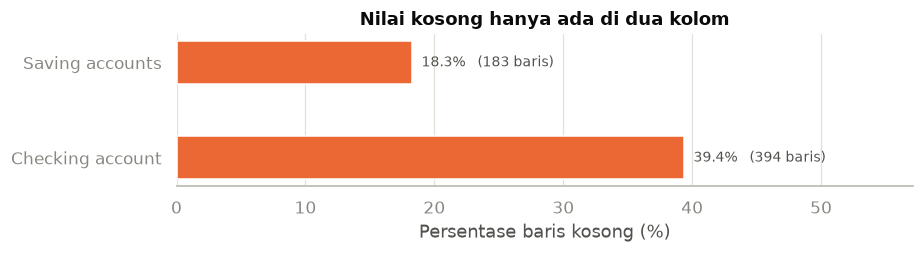

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 2.4))
kolom_kosong = missing.index.tolist()
ax.barh(kolom_kosong, missing["persentase"], color=ORANYE, height=0.45)
for i, kol in enumerate(kolom_kosong):
    pct = missing.loc[kol, "persentase"]
    ax.text(pct + 0.7, i, f"{pct}%   ({missing.loc[kol, 'jumlah_kosong']} baris)",
            va="center", color=TINTA2, fontsize=9)
ax.set_xlim(0, missing["persentase"].max() * 1.45)
ax.set_xlabel("Persentase baris kosong (%)")
ax.set_title("Nilai kosong hanya ada di dua kolom")
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

### 2.2 Data duplikat

In [9]:
jml_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat: {jml_duplikat}")

# Dicek ke seluruh kolom sekaligus; dua nasabah boleh punya nilai yang kebetulan sama.
if jml_duplikat == 0:
    print("-> Tidak ada baris yang benar-benar kembar. Tidak ada yang perlu dibuang.")

Jumlah baris duplikat: 0
-> Tidak ada baris yang benar-benar kembar. Tidak ada yang perlu dibuang.


### 2.3 Outlier

In [10]:
# Metode IQR: nilai di luar [Q1 - 1,5*IQR, Q3 + 1,5*IQR] jadi kandidat outlier.
ringkasan = []
for kol in KOLOM_NUMERIK:
    q1, q3 = df[kol].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[kol] < batas_bawah) | (df[kol] > batas_atas)).sum())
    ringkasan.append({
        "kolom": kol, "Q1": q1, "Q3": q3, "IQR": iqr,
        "batas_bawah": batas_bawah, "batas_atas": batas_atas,
        "jml_outlier": n_out, "persen": round(n_out / len(df) * 100, 1),
    })

pd.DataFrame(ringkasan).set_index("kolom").round(2)

,Q1,Q3,IQR,batas_bawah,batas_atas,jml_outlier,persen
kolom,,,,,,,
Age,27.0,42.00,15.00,4.50,64.50,23,2.3
Credit amount,1365.5,3972.25,2606.75,-2544.62,7882.38,72,7.2
Duration,12.0,24.00,12.00,-6.00,42.00,70,7.0


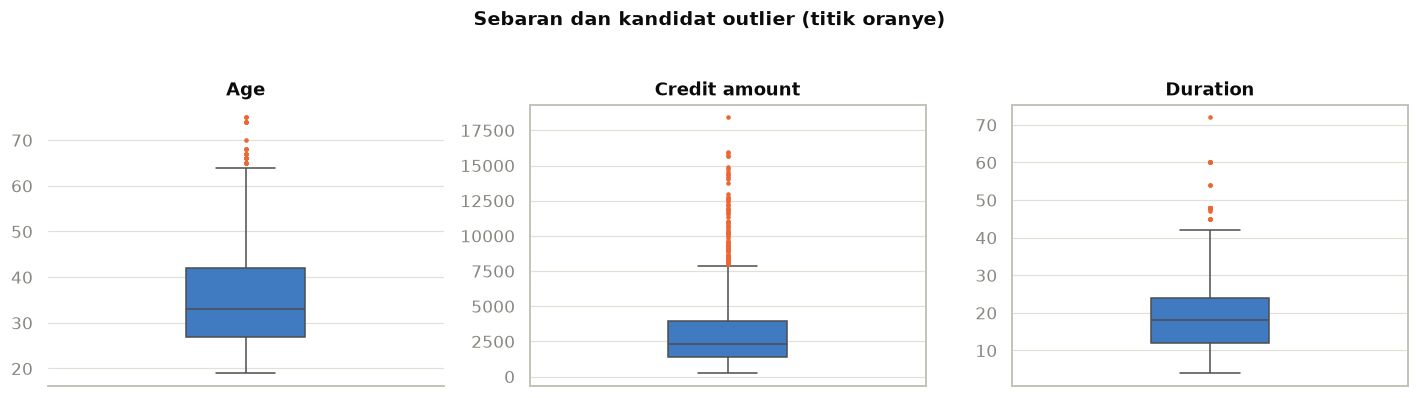

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, kol in zip(axes, KOLOM_NUMERIK):
    sns.boxplot(y=df[kol], ax=ax, color=BIRU, width=0.3,
                flierprops=dict(marker="o", markersize=3,
                                markerfacecolor=ORANYE, markeredgecolor="none"))
    ax.set_title(kol)
    ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
sns.despine(ax=axes[0], left=True)
plt.suptitle("Sebaran dan kandidat outlier (titik oranye)", y=1.05,
             fontsize=12.5, fontweight="bold", color=TINTA)
plt.tight_layout()
plt.show()

### 2.4 Penanganan missing value

In [12]:
# "NA" jadi kategori "unknown", bukan diisi mean/modus - kosong di kolom saldo
# memang berarti ada, dan mengisinya sama dengan mengarang data.
df["Saving accounts"] = df["Saving accounts"].fillna("unknown")
df["Checking account"] = df["Checking account"].fillna("unknown")

print("Setelah penanganan:")
print("  Saving accounts  :", df["Saving accounts"].value_counts().to_dict())
print("  Checking account :", df["Checking account"].value_counts().to_dict())
print()
print("Total nilai kosong tersisa:", int(df.isna().sum().sum()))

Setelah penanganan:
  Saving accounts  : {'little': 603, 'unknown': 183, 'moderate': 103, 'quite rich': 63, 'rich': 48}
  Checking account : {'unknown': 394, 'little': 274, 'moderate': 269, 'rich': 63}

Total nilai kosong tersisa: 0


---
## 3. EDA & ExDA

### 3.1 Statistik deskriptif

In [13]:
print("Kolom numerik:")
df.describe().round(2)

Kolom numerik:


,Age,Job,Credit amount,Duration
count,1000.00,1000.00,1000.00,1000.00
mean,35.55,1.90,3271.26,20.90
std,11.38,0.65,2822.74,12.06
min,19.00,0.00,250.00,4.00
25%,27.00,2.00,1365.50,12.00
50%,33.00,2.00,2319.50,18.00
75%,42.00,2.00,3972.25,24.00
max,75.00,3.00,18424.00,72.00


In [14]:
print("Kolom kategorikal:")
ringkas = pd.DataFrame({
    "jumlah_unik": [df[c].nunique() for c in KOLOM_KATEGORIKAL + KOLOM_JOB + [TARGET]],
    "nilai_tersering": [df[c].value_counts().index[0] for c in KOLOM_KATEGORIKAL + KOLOM_JOB + [TARGET]],
    "frekuensi": [int(df[c].value_counts().iloc[0]) for c in KOLOM_KATEGORIKAL + KOLOM_JOB + [TARGET]],
}, index=KOLOM_KATEGORIKAL + KOLOM_JOB + [TARGET])
ringkas["persen"] = (ringkas["frekuensi"] / len(df) * 100).round(1)
ringkas

Kolom kategorikal:


,jumlah_unik,nilai_tersering,frekuensi,persen
Sex,2,male,690,69.0
Housing,3,own,713,71.3
Purpose,8,car,337,33.7
Saving accounts,5,little,603,60.3
Checking account,4,unknown,394,39.4
Job,4,2,630,63.0
Risk,2,good,700,70.0


### 3.2 Distribusi kolom numerik

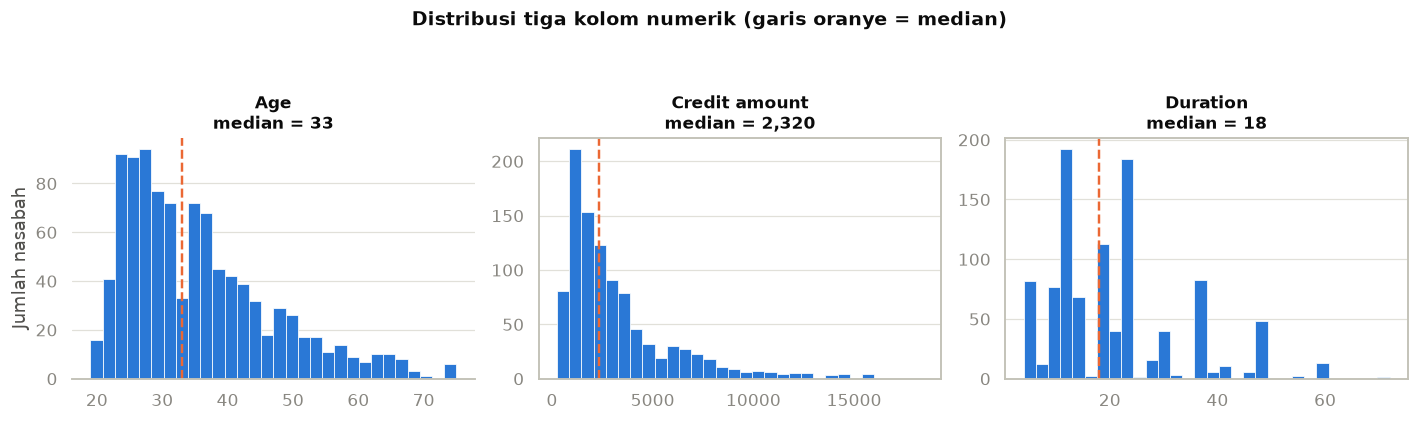

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, kol in zip(axes, KOLOM_NUMERIK):
    median = df[kol].median()
    ax.hist(df[kol], bins=30, color=BIRU, edgecolor="white", linewidth=0.5)
    ax.axvline(median, color=ORANYE, linestyle="--", linewidth=1.6)
    ax.set_title(f"{kol}\nmedian = {median:,.0f}", fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Jumlah nasabah")
sns.despine(ax=axes[0], left=True)
plt.suptitle("Distribusi tiga kolom numerik (garis oranye = median)", y=1.08,
             fontsize=12.5, fontweight="bold", color=TINTA)
plt.tight_layout()
plt.show()

In [16]:
# Ukuran kemencengan (skewness): 0 = simetris, > 0 = menceng ke kanan.
print("Kemencengan (skewness):")
print(df[KOLOM_NUMERIK].skew().round(2).to_string())

Kemencengan (skewness):
Age              1.02
Credit amount    1.95
Duration         1.09


### 3.3 Distribusi kolom kategorikal

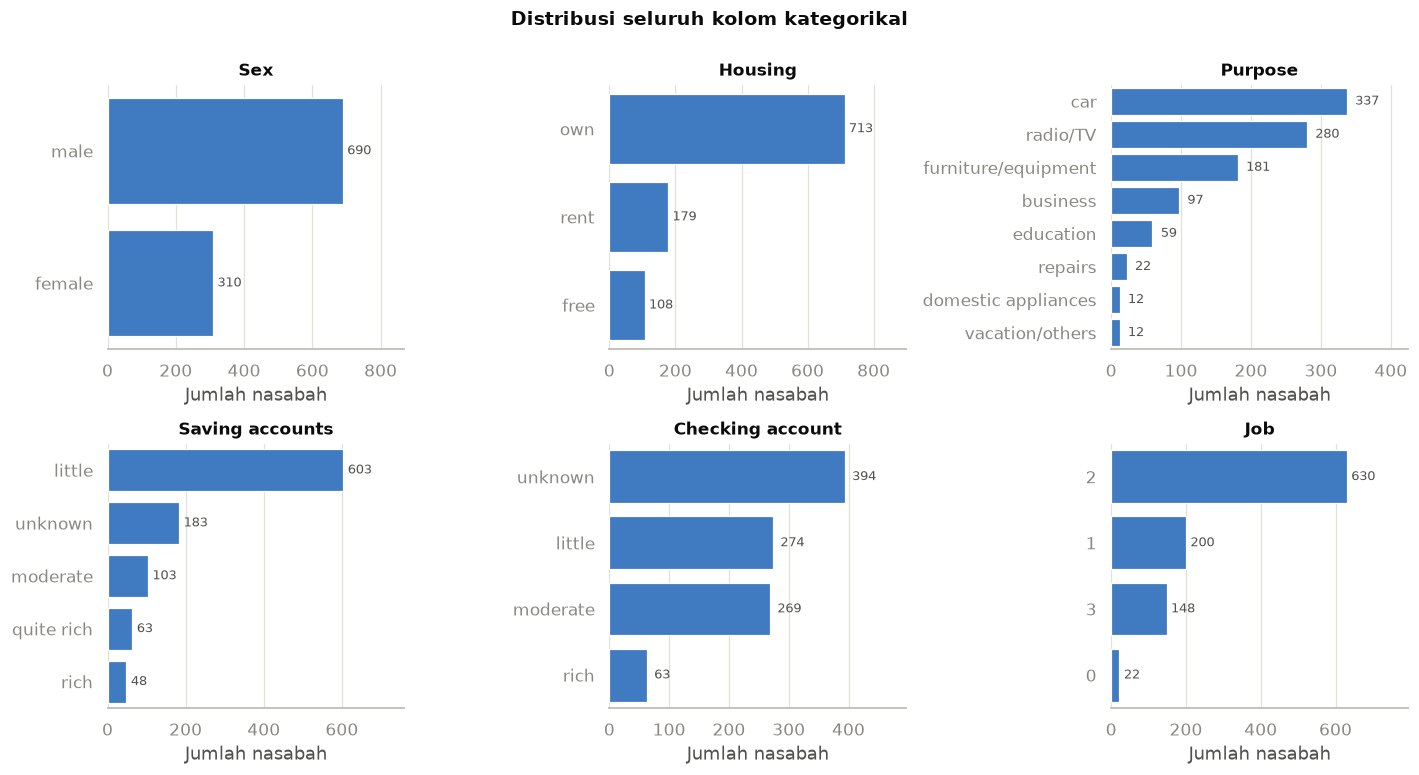

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, kol in zip(axes.ravel(), KOLOM_KATEGORIKAL + KOLOM_JOB):
    urut = df[kol].value_counts().index
    sns.countplot(data=df, y=kol, order=urut, ax=ax, color=BIRU,
                  edgecolor="white", linewidth=0.8)
    ax.set_title(kol, fontsize=11)
    ax.set_xlabel("Jumlah nasabah")
    ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, ax.get_xlim()[1] * 1.20)
    for p in ax.patches:  # label langsung di ujung batang
        ax.text(p.get_width() + len(df) * 0.012, p.get_y() + p.get_height() / 2,
                f"{int(p.get_width())}", va="center", fontsize=8.5, color=TINTA2)
    sns.despine(ax=ax, left=True)
plt.suptitle("Distribusi seluruh kolom kategorikal", y=1.0,
             fontsize=12.5, fontweight="bold", color=TINTA)
plt.tight_layout()
plt.show()

### 3.4 Distribusi kelas target — temuan terpenting di tahap EDA

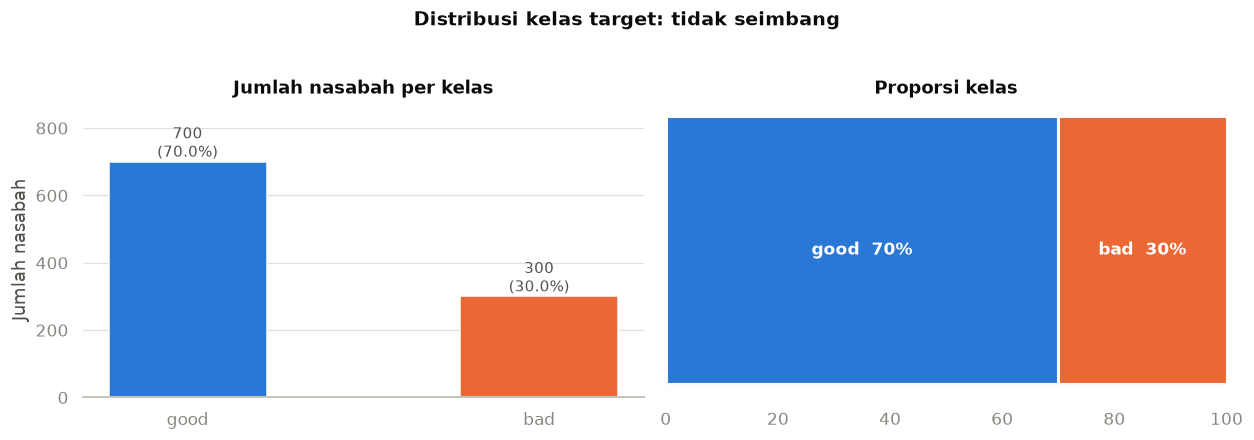

Risk
good    700
bad     300

Rasio good : bad = 2.33 : 1


In [18]:
hitungan = df[TARGET].value_counts()
persen = df[TARGET].value_counts(normalize=True) * 100
warna_target = {"good": BIRU, "bad": ORANYE}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

# --- kiri: jumlah absolut
axes[0].bar(hitungan.index, hitungan.values,
            color=[warna_target[k] for k in hitungan.index], width=0.45)
for i, k in enumerate(hitungan.index):
    axes[0].text(i, hitungan[k] + 15, f"{hitungan[k]}\n({persen[k]:.1f}%)",
                 ha="center", color=TINTA2, fontsize=10)
axes[0].set_title("Jumlah nasabah per kelas")
axes[0].set_ylabel("Jumlah nasabah")
axes[0].set_ylim(0, hitungan.max() * 1.25)
axes[0].grid(axis="x", visible=False)
sns.despine(ax=axes[0], left=True)

# --- kanan: proporsi dalam satu batang
axes[1].barh(["Seluruh data"], [persen["good"]], color=BIRU, height=0.32,
             edgecolor="#fcfcfb", linewidth=2)
axes[1].barh(["Seluruh data"], [persen["bad"]], left=[persen["good"]], color=ORANYE,
             height=0.32, edgecolor="#fcfcfb", linewidth=2)
axes[1].text(persen["good"] / 2, 0, f"good  {persen['good']:.0f}%", ha="center",
             va="center", color="white", fontsize=11, fontweight="bold")
axes[1].text(persen["good"] + persen["bad"] / 2, 0, f"bad  {persen['bad']:.0f}%",
             ha="center", va="center", color="white", fontsize=11, fontweight="bold")
axes[1].set_xlim(0, 100)
axes[1].set_title("Proporsi kelas")
axes[1].set_yticks([])
axes[1].grid(visible=False)
sns.despine(ax=axes[1], left=True, bottom=True)

plt.suptitle("Distribusi kelas target: tidak seimbang", y=1.04,
             fontsize=12.5, fontweight="bold", color=TINTA)
plt.tight_layout()
plt.show()

print(df[TARGET].value_counts().to_string())
print()
print(f"Rasio good : bad = {hitungan['good'] / hitungan['bad']:.2f} : 1")

### 3.5 Hubungan fitur numerik dengan target (ExDA)

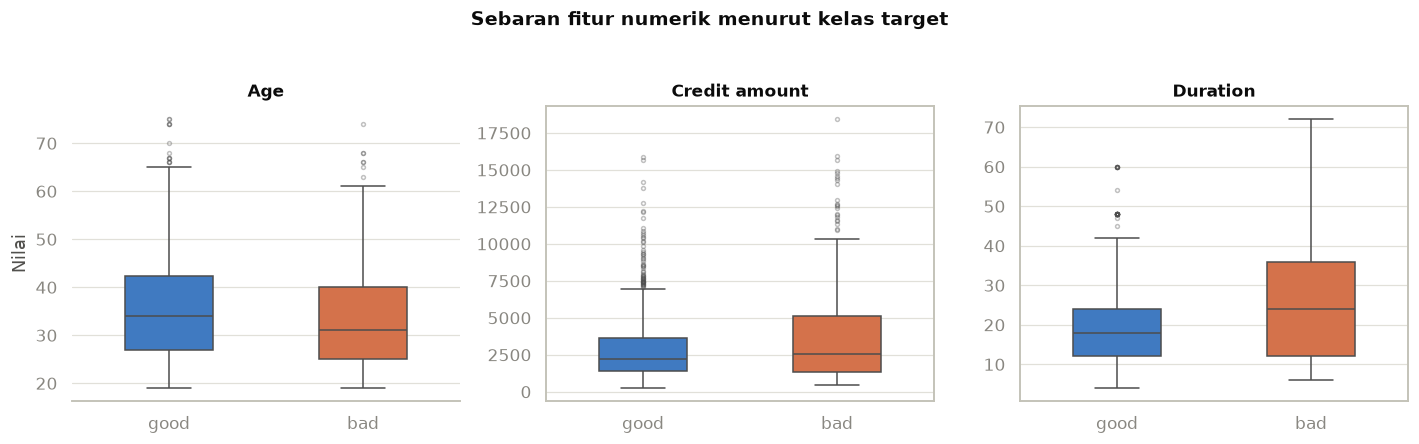

Median tiap kelas:
       Age  Credit amount  Duration
Risk                               
bad   31.0         2574.5      24.0
good  34.0         2244.0      18.0

Rata-rata tiap kelas:
       Age  Credit amount  Duration
Risk                               
bad   34.0         3938.1      24.9
good  36.2         2985.5      19.2


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, kol in zip(axes, KOLOM_NUMERIK):
    sns.boxplot(data=df, x=TARGET, y=kol, order=["good", "bad"], ax=ax,
                hue=TARGET, palette=warna_target, legend=False, width=0.45,
                flierprops=dict(marker="o", markersize=2.5, alpha=0.35))
    ax.set_title(kol, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Nilai")
sns.despine(ax=axes[0], left=True)
plt.suptitle("Sebaran fitur numerik menurut kelas target", y=1.05,
             fontsize=12.5, fontweight="bold", color=TINTA)
plt.tight_layout()
plt.show()

print("Median tiap kelas:")
print(df.groupby(TARGET)[KOLOM_NUMERIK].median().round(1).to_string())
print()
print("Rata-rata tiap kelas:")
print(df.groupby(TARGET)[KOLOM_NUMERIK].mean().round(1).to_string())

### 3.6 Hubungan fitur kategorikal dengan target (ExDA)

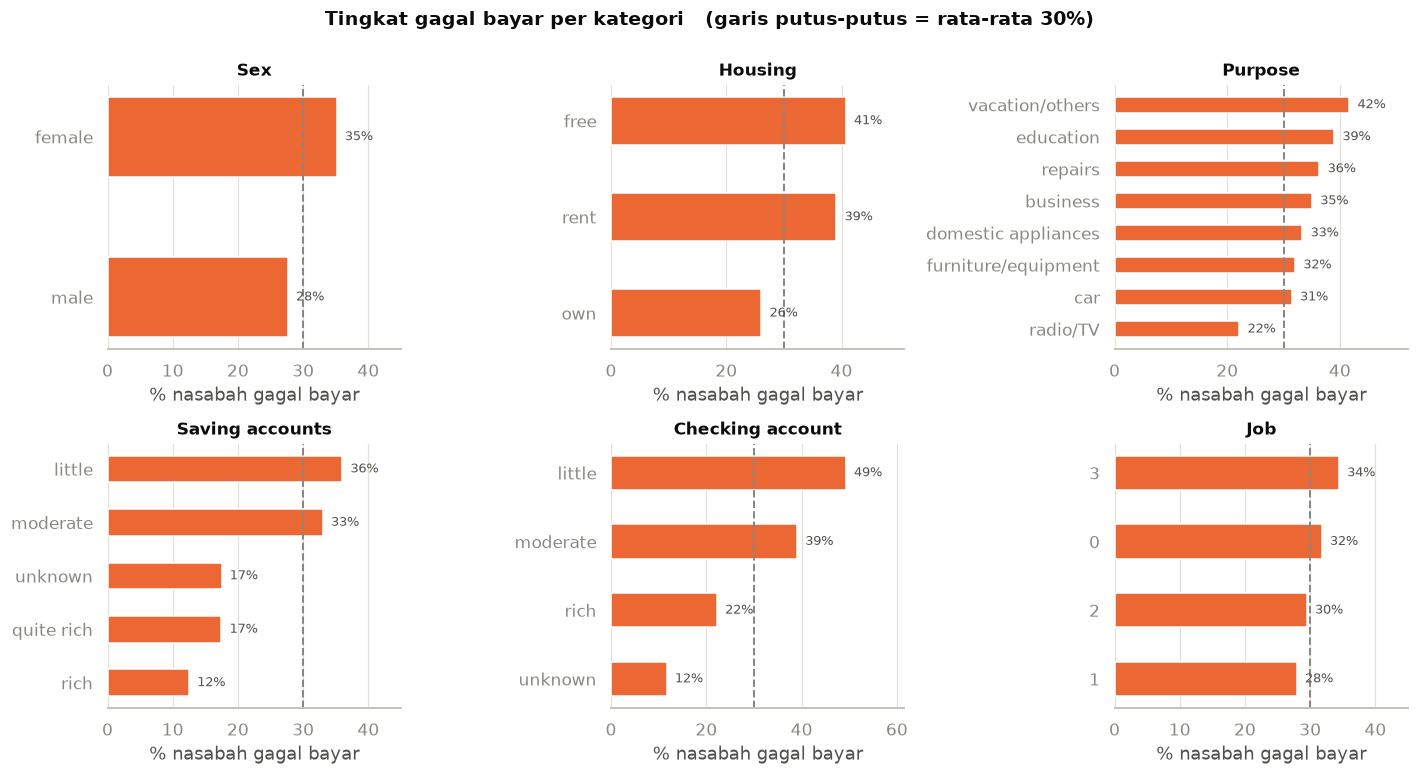

In [20]:
# Yang dibaca di sini tingkat risiko tiap kategori, bukan jumlah nasabahnya.
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, kol in zip(axes.ravel(), KOLOM_KATEGORIKAL + KOLOM_JOB):
    tingkat = (df.assign(is_bad=(df[TARGET] == "bad").astype(int))
                 .groupby(kol)["is_bad"].mean().mul(100)
                 .sort_values(ascending=True))
    ax.barh(tingkat.index.astype(str), tingkat.values, color=ORANYE, height=0.5)
    ax.axvline(30, color=ABU, linestyle="--", linewidth=1.3)
    ax.set_xlim(0, max(tingkat.max() * 1.25, 45))
    ax.set_title(kol, fontsize=11)
    ax.set_xlabel("% nasabah gagal bayar")
    ax.set_ylabel("")
    ax.grid(axis="y", visible=False)
    for i, v in enumerate(tingkat.values):
        ax.text(v + tingkat.max() * 0.035, i, f"{v:.0f}%", va="center",
                fontsize=8.5, color=TINTA2)
    sns.despine(ax=ax, left=True)
plt.suptitle("Tingkat gagal bayar per kategori   (garis putus-putus = rata-rata 30%)",
             y=1.0, fontsize=12.5, fontweight="bold", color=TINTA)
plt.tight_layout()
plt.show()

In [21]:
# Tabel angka lengkapnya, supaya bisa dibaca lebih teliti daripada dari grafik.
for kol in ["Checking account", "Saving accounts", "Purpose", "Housing", "Sex", "Job"]:
    t = (df.assign(is_bad=(df[TARGET] == "bad").astype(int))
           .groupby(kol)
           .agg(jumlah=("is_bad", "size"), tingkat_bad=("is_bad", lambda s: round(s.mean() * 100, 1)))
           .sort_values("tingkat_bad", ascending=False))
    print(f"--- {kol}")
    print(t.to_string(), "\n")

--- Checking account
                  jumlah  tingkat_bad
Checking account                     
little               274         49.3
moderate             269         39.0
rich                  63         22.2
unknown              394         11.7 

--- Saving accounts
                 jumlah  tingkat_bad
Saving accounts                     
little              603         36.0
moderate            103         33.0
quite rich           63         17.5
unknown             183         17.5
rich                 48         12.5 

--- Purpose
                     jumlah  tingkat_bad
Purpose                                 
vacation/others          12         41.7
education                59         39.0
repairs                  22         36.4
business                 97         35.1
domestic appliances      12         33.3
furniture/equipment     181         32.0
car                     337         31.5
radio/TV                280         22.1 

--- Housing
         jumlah  tingkat_bad
Hou

### 3.7 Matriks korelasi

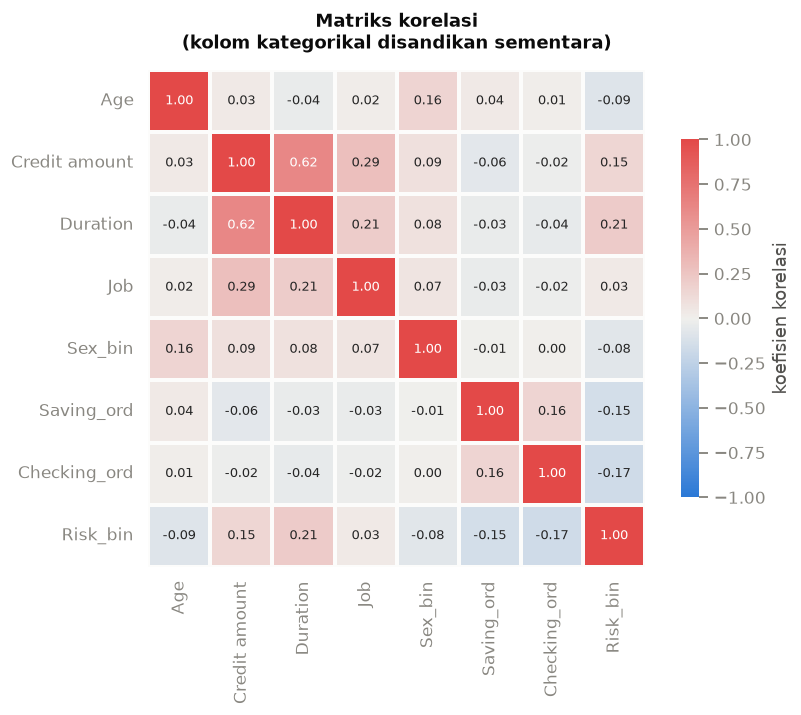

In [22]:
# Kolom kategorikal disandikan SEMENTARA, khusus untuk korelasi ini - bukan untuk model.
# Penyandian yang dipakai model dilakukan di tahap Data Processing.
df_kor = df.copy()
df_kor["Risk_bin"] = (df_kor[TARGET] == "bad").astype(int)
df_kor["Sex_bin"] = (df_kor["Sex"] == "male").astype(int)
# "unknown" dibiarkan kosong karena tidak berada di skala little < moderate < rich.
df_kor["Saving_ord"] = df_kor["Saving accounts"].map(
    {"little": 1, "moderate": 2, "quite rich": 3, "rich": 4})
df_kor["Checking_ord"] = df_kor["Checking account"].map(
    {"little": 1, "moderate": 2, "rich": 3})

kolom_kor = KOLOM_NUMERIK + ["Job", "Sex_bin", "Saving_ord", "Checking_ord", "Risk_bin"]
kor = df_kor[kolom_kor].corr()

fig, ax = plt.subplots(figsize=(8.2, 6.6))
sns.heatmap(kor, annot=True, fmt=".2f", cmap=CMAP_DIVERGEN, center=0, vmin=-1, vmax=1,
            square=True, linewidths=1.5, linecolor="#fcfcfb",
            cbar_kws={"shrink": 0.72, "label": "koefisien korelasi"},
            annot_kws={"fontsize": 8.5}, ax=ax)
ax.set_title("Matriks korelasi\n(kolom kategorikal disandikan sementara)", pad=14)
ax.grid(visible=False)
plt.tight_layout()
plt.show()

In [23]:
# Urutan korelasi terhadap target, dari yang terkuat.
print("Korelasi tiap fitur terhadap Risk_bin (bad = 1):")
print(kor["Risk_bin"].drop("Risk_bin").sort_values(key=abs, ascending=False).round(3).to_string())

Korelasi tiap fitur terhadap Risk_bin (bad = 1):
Duration         0.215
Checking_ord    -0.165
Credit amount    0.155
Saving_ord      -0.145
Age             -0.091
Sex_bin         -0.075
Job              0.033


---
## 4. Data Processing

In [24]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", StandardScaler(), KOLOM_NUMERIK),
        ("kategorikal", OneHotEncoder(handle_unknown="ignore"), KOLOM_KATEGORIKAL),
        ("job", "passthrough", KOLOM_JOB),
    ],
    remainder="drop",
)

print("Preprocessor siap - tetapi BELUM di-fit. Itu dilakukan setelah split.")
print()
print("  numerik     :", KOLOM_NUMERIK, "-> StandardScaler")
print("  kategorikal :", KOLOM_KATEGORIKAL, "-> OneHotEncoder")
print("  dibiarkan   :", KOLOM_JOB)

Preprocessor siap - tetapi BELUM di-fit. Itu dilakukan setelah split.

  numerik     : ['Age', 'Credit amount', 'Duration'] -> StandardScaler
  kategorikal : ['Sex', 'Housing', 'Purpose', 'Saving accounts', 'Checking account'] -> OneHotEncoder
  dibiarkan   : ['Job']


In [25]:
# Ilustrasi mengapa scaling diperlukan: bandingkan rentang sebelum dan sesudah.
contoh = df[KOLOM_NUMERIK].head()
print("SEBELUM scaling (5 baris pertama):")
print(contoh.to_string(index=False))
print()
print("Rentang tiap kolom:")
print((df[KOLOM_NUMERIK].max() - df[KOLOM_NUMERIK].min()).to_string())
print()
print("SESUDAH scaling (fit pada data train saja nanti):")
print("  setiap kolom akan punya rata-rata ~0 dan simpangan baku ~1,")
print("  sehingga tidak ada kolom yang mendominasi hanya karena satuannya besar.")

SEBELUM scaling (5 baris pertama):
 Age  Credit amount  Duration
  67           1169         6
  22           5951        48
  49           2096        12
  45           7882        42
  53           4870        24

Rentang tiap kolom:
Age                 56
Credit amount    18174
Duration            68

SESUDAH scaling (fit pada data train saja nanti):
  setiap kolom akan punya rata-rata ~0 dan simpangan baku ~1,
  sehingga tidak ada kolom yang mendominasi hanya karena satuannya besar.


---
## 5. Data Splitting

In [26]:
X = df[SEMUA_FITUR]
y = df[TARGET]          # masih berupa teks "good" / "bad"

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% untuk uji
    random_state=RANDOM_STATE,
    stratify=y,           # jaga proporsi kelas di kedua bagian
)

print(f"Data train : {X_train.shape[0]} baris")
print(f"Data test  : {X_test.shape[0]} baris")
print()
print("Proporsi kelas di data TRAIN:")
print((y_train.value_counts(normalize=True) * 100).round(1).to_string())
print()
print("Proporsi kelas di data TEST:")
print((y_test.value_counts(normalize=True) * 100).round(1).to_string())

Data train : 800 baris
Data test  : 200 baris

Proporsi kelas di data TRAIN:
Risk
good    70.0
bad     30.0

Proporsi kelas di data TEST:
Risk
good    70.0
bad     30.0


---
## 6. Pembangunan Model

In [27]:
def evaluasi(nama, model, X_test, y_test):
    """Hitung metrik klasifikasi dan kembalikan sebagai satu baris tabel."""
    y_pred = model.predict(X_test)
    # PENTING: classes_ urut alfabet = ['bad', 'good'], jadi indeks 1 = peluang "good".
    # Indeksnya dicari lewat nama kelas; hardcode [:, 1] akan membalik AUC.
    idx_bad = list(model.classes_).index("bad")
    y_proba = model.predict_proba(X_test)[:, idx_bad]

    return {
        "Model": nama,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="bad", zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label="bad", zero_division=0),
        "F1": f1_score(y_test, y_pred, pos_label="bad", zero_division=0),
        "ROC-AUC": roc_auc_score((y_test == "bad").astype(int), y_proba),
    }


def gambar_confusion(nama, model, ax, y_test):
    """Gambar confusion matrix dengan skala warna biru berurutan."""
    cm = confusion_matrix(y_test, model.predict(X_test), labels=["good", "bad"])
    sns.heatmap(cm, annot=True, fmt="d", cmap=CMAP_URUT, ax=ax, cbar=False,
                linewidths=2, linecolor="#fcfcfb",
                annot_kws={"fontsize": 13, "fontweight": "bold"},
                xticklabels=["good", "bad"], yticklabels=["good", "bad"])
    ax.set_title(nama, fontsize=11)
    ax.set_xlabel("Prediksi model")
    ax.set_ylabel("Kenyataan")
    ax.grid(visible=False)


hasil = []          # menampung satu baris metrik per model
model_utama = {}    # menyimpan objek model yang sudah dilatih
print("Fungsi evaluasi siap.")

Fungsi evaluasi siap.


### 6.1 Baseline dan Logistic Regression

In [28]:
# --- Baseline: selalu menebak kelas mayoritas ("good") ---
# Bukan model sungguhan - hanya batas bawah, angka tanpa belajar apa pun dari data.
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
hasil.append(evaluasi("Baseline (selalu 'good')", dummy, X_test, y_test))

# --- Logistic Regression ---
# max_iter dinaikkan ke 1000 karena solver butuh lebih banyak iterasi setelah scaling.
# class_weight="balanced" membuat kesalahan pada kelas "bad" dihitung lebih mahal.
lr = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE,
                                 class_weight="balanced")),
])
lr.fit(X_train, y_train)
hasil.append(evaluasi("Logistic Regression", lr, X_test, y_test))
model_utama["Logistic Regression"] = lr

print("Selesai: baseline + Logistic Regression")
print()
print("Bobot kelas yang dipakai model:")
n_latih = len(y_train)
for kelas, jumlah in y_train.value_counts().items():
    bobot = n_latih / (2 * jumlah)
    print(f"  {kelas:5s}: {jumlah:4d} baris -> bobot {bobot:.3f}")

Selesai: baseline + Logistic Regression

Bobot kelas yang dipakai model:
  good :  560 baris -> bobot 0.714
  bad  :  240 baris -> bobot 1.667


### 6.2 Decision Tree dan Random Forest

In [29]:
# Dikumpulkan di satu tempat supaya bisa dipakai ulang di versi tanpa pembobotan.
PARAMETER_DT = dict(
    criterion="gini",        # ukuran ketidakmurnian saat memilih pemisahan
    max_depth=10,            # batas kedalaman pohon
    min_samples_split=10,    # minimal baris untuk membentuk cabang baru
    min_samples_leaf=5,      # minimal baris dalam satu daun
    random_state=RANDOM_STATE,
)

# --- Decision Tree ---
# Tanpa batas kedalaman, satu pohon akan menghafal data train.
dt = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(**PARAMETER_DT, class_weight="balanced")),
])
dt.fit(X_train, y_train)
hasil.append(evaluasi("Decision Tree (max_depth=10)", dt, X_test, y_test))
model_utama["Decision Tree"] = dt

# --- Random Forest ---
# Suara terbanyak dari 100 pohon - yang salah tebak saling menutupi.
rf = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE,
                                     class_weight="balanced")),
])
rf.fit(X_train, y_train)
hasil.append(evaluasi("Random Forest (100 pohon)", rf, X_test, y_test))
model_utama["Random Forest"] = rf

print("Selesai: Decision Tree + Random Forest")

Selesai: Decision Tree + Random Forest


### 6.3 Perbandingan hasil

In [30]:
tabel = pd.DataFrame(hasil).set_index("Model")
# Tampilkan selalu 3 angka di belakang koma, supaya kolomnya rapi sejajar.
with pd.option_context("display.float_format", "{:.3f}".format):
    display(tabel.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Baseline (selalu 'good'),0.700,0.000,0.000,0.000,0.500
Logistic Regression,0.645,0.446,0.750,0.559,0.753
Decision Tree (max_depth=10),0.610,0.400,0.600,0.480,0.669
Random Forest (100 pohon),0.705,0.506,0.650,0.569,0.761


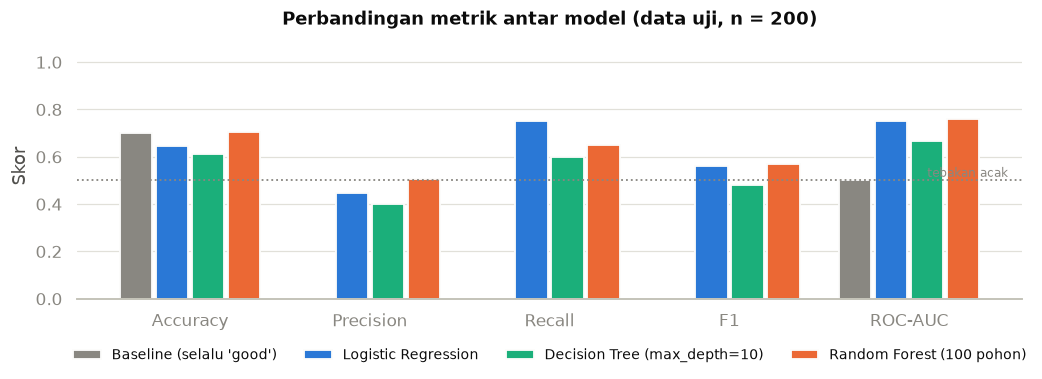

In [31]:
fig, ax = plt.subplots(figsize=(10, 3.6))
metrik = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
x = np.arange(len(metrik))
lebar = 0.2
warna_model = [ABU, BIRU, "#1baf7a", ORANYE]

for i, (nama, baris) in enumerate(tabel.iterrows()):
    nilai = [baris[m] for m in metrik]
    pos = x + (i - 1.5) * lebar
    ax.bar(pos, nilai, lebar * 0.9, label=nama, color=warna_model[i],
           edgecolor="#fcfcfb", linewidth=1.2)

ax.axhline(0.5, color=ABU, linestyle=":", linewidth=1.2)
ax.text(len(metrik) - 0.45, 0.515, "tebakan acak", fontsize=8, color=ABU, ha="right")
ax.set_xticks(x)
ax.set_xticklabels(metrik)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Skor")
ax.set_title("Perbandingan metrik antar model (data uji, n = 200)")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          fontsize=9)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

### Seberapa besar efek pembobotan kelas?

In [32]:
# Model yang sama, TANPA class_weight - hanya sebagai pembanding.
tanpa_bobot = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(**PARAMETER_DT)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
    ]),
}
for m in tanpa_bobot.values():
    m.fit(X_train, y_train)

banding = []
for nama, m in tanpa_bobot.items():
    a = evaluasi(nama, m, X_test, y_test)          # tanpa pembobotan
    b = evaluasi(nama, model_utama[nama], X_test, y_test)   # dengan pembobotan
    banding.append({
        "Model": nama,
        "Accuracy tanpa": a["Accuracy"], "Accuracy balanced": b["Accuracy"],
        "Recall tanpa": a["Recall"], "Recall balanced": b["Recall"],
        "ROC-AUC tanpa": a["ROC-AUC"], "ROC-AUC balanced": b["ROC-AUC"],
    })

with pd.option_context("display.float_format", "{:.3f}".format):
    display(pd.DataFrame(banding).set_index("Model").round(3))

,Accuracy tanpa,Accuracy balanced,Recall tanpa,Recall balanced,ROC-AUC tanpa,ROC-AUC balanced
Model,,,,,,
Logistic Regression,0.735,0.645,0.450,0.750,0.751,0.753
Decision Tree,0.725,0.610,0.500,0.600,0.713,0.669
Random Forest,0.730,0.705,0.483,0.650,0.750,0.761


### 6.4 Confusion matrix

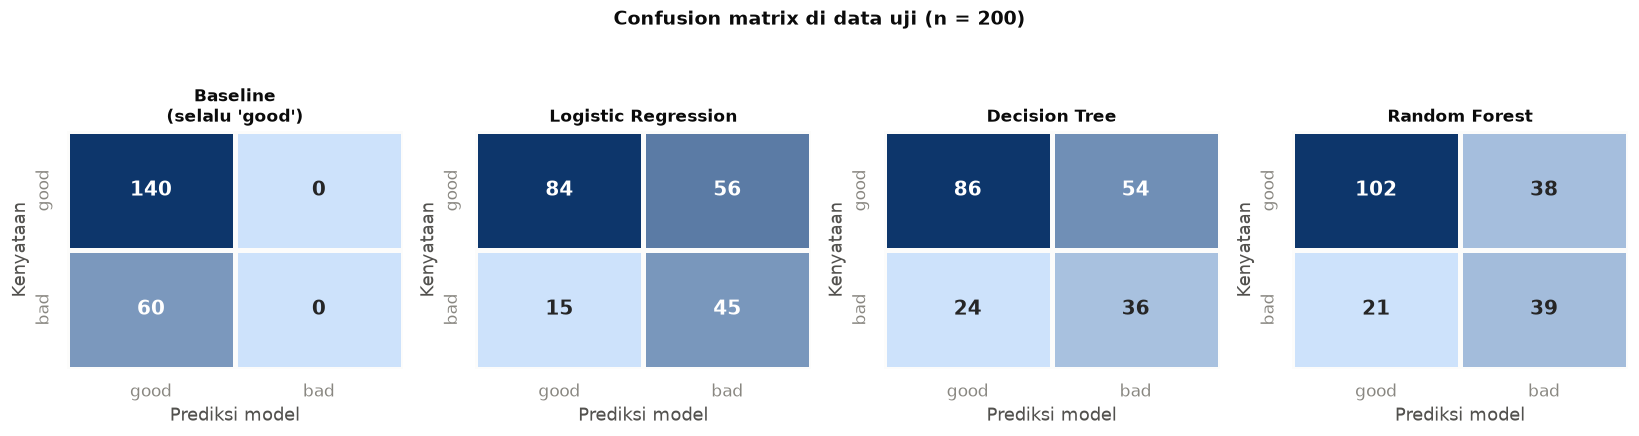

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7))
for ax, (nama, model) in zip(axes, [("Baseline\n(selalu 'good')", dummy),
                                     ("Logistic Regression", lr),
                                     ("Decision Tree", dt),
                                     ("Random Forest", rf)]):
    gambar_confusion(nama, model, ax, y_test)
plt.suptitle("Confusion matrix di data uji (n = 200)", y=1.06,
             fontsize=12.5, fontweight="bold", color=TINTA)
plt.tight_layout()
plt.show()

In [34]:
print("Laporan klasifikasi lengkap - Random Forest")
print("=" * 58)
print(classification_report(y_test, rf.predict(X_test), digits=3))

Laporan klasifikasi lengkap - Random Forest
              precision    recall  f1-score   support

         bad      0.506     0.650     0.569        60
        good      0.829     0.729     0.776       140

    accuracy                          0.705       200
   macro avg      0.668     0.689     0.673       200
weighted avg      0.732     0.705     0.714       200



### 6.5 Fitur yang paling berpengaruh

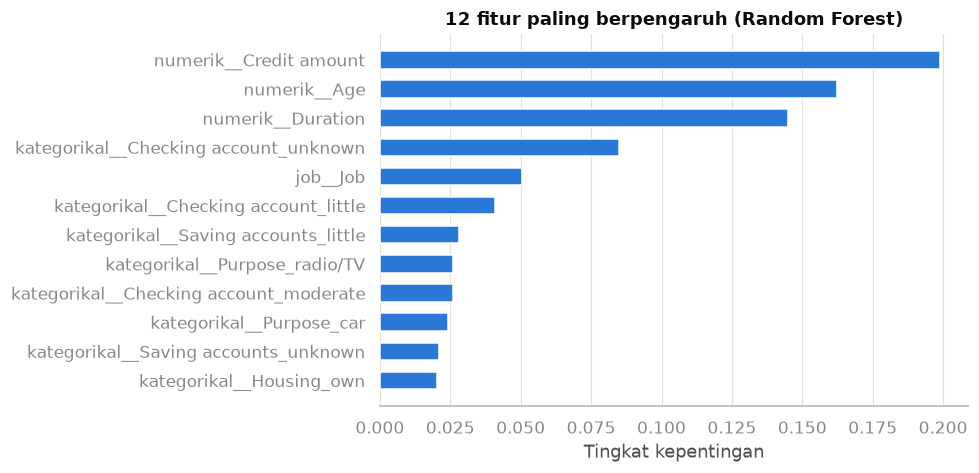

In [35]:
# Random Forest bisa melaporkan seberapa besar tiap fitur dipakai untuk memisahkan kelas.
nama_fitur = rf.named_steps["preprocessor"].get_feature_names_out()
kepentingan = (pd.Series(rf.named_steps["model"].feature_importances_, index=nama_fitur)
                 .sort_values(ascending=False).head(12))

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(kepentingan.index[::-1], kepentingan.values[::-1], color=BIRU, height=0.6)
ax.set_title("12 fitur paling berpengaruh (Random Forest)", fontsize=12)
ax.set_xlabel("Tingkat kepentingan")
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

### 6.6 Pemeriksaan atribut sensitif

In [36]:
# Sex ikut dilatih, jadi perlu diperiksa apakah model memperlakukan kedua kelompok berbeda.
pred_test = rf.predict(X_test)

print("Prediksi model menurut jenis kelamin (data uji):")
print((pd.crosstab(X_test["Sex"], pred_test, normalize="index") * 100).round(1).to_string())
print()
print("Kenyataan menurut jenis kelamin (data uji):")
print((pd.crosstab(X_test["Sex"], y_test, normalize="index") * 100).round(1).to_string())

Prediksi model menurut jenis kelamin (data uji):
col_0    bad  good
Sex               
female  46.7  53.3
male    35.0  65.0

Kenyataan menurut jenis kelamin (data uji):
Risk     bad  good
Sex               
female  33.3  66.7
male    28.6  71.4


---
## 7. Deployment: Menyimpan dan Memuat Model

Deployment adalah proses mengintegrasikan model hasil pelatihan ke dalam aplikasi atau sistem
produksi, sehingga model bisa dipakai oleh pengguna akhir. Monitoring adalah kelanjutannya:
memastikan model tetap bekerja baik setelah di-deploy, dan mendeteksi sedini mungkin kalau
kinerjanya turun.

Sampai bagian 6, model hanya hidup di dalam memori notebook ini. Begitu notebook ditutup,
modelnya hilang. Karena itu langkah pertama deployment adalah **menyimpan model ke berkas**.

### 7.1 Menyimpan model ke joblib dan pickle

Dua format, isinya sama:

- **joblib** — cara bawaan scikit-learn, paling cepat untuk objek besar berisi array numpy.
- **pickle** — format standar Python, bisa dibaca di mana saja tanpa joblib.

Yang disimpan adalah **pipeline utuh** (preprocessor + model), bukan hanya modelnya. Kalau yang
disimpan cuma modelnya, service API harus mengulang sendiri proses scaling dan one-hot encoding
- dan ketidakcocokan di langkah itu adalah sumber bug yang paling sering terjadi saat deployment.

In [37]:
import pickle
from pathlib import Path

import joblib

FOLDER_MODEL = Path("model")
FOLDER_MODEL.mkdir(exist_ok=True)

BERKAS_JOBLIB = FOLDER_MODEL / "credit_risk_model.joblib"
BERKAS_PICKLE = FOLDER_MODEL / "credit_risk_model.pkl"

# Model yang di-deploy: Random Forest - ROC-AUC dan F1-nya paling tinggi di bagian 6.
model_final = rf

joblib.dump(model_final, BERKAS_JOBLIB)
with open(BERKAS_PICKLE, "wb") as file:
    pickle.dump(model_final, file)

print("Model tersimpan:")
for berkas in sorted(FOLDER_MODEL.iterdir()):
    print(f"  {berkas}  ->  {berkas.stat().st_size / 1024:,.0f} KB")

Model tersimpan:
  model/credit_risk_model.joblib  ->  3,360 KB
  model/credit_risk_model.pkl  ->  3,355 KB


In [38]:
# Langkah pertama deployment: memuat kembali model yang sudah disimpan.
joblib_model = joblib.load(BERKAS_JOBLIB)

with open(BERKAS_PICKLE, "rb") as file:
    pickle_model = pickle.load(file)

# Model hasil muat harus menjawab persis sama dengan model yang masih di memori.
pred_asli = model_final.predict(X_test)

print("Prediksi identik dengan model di memori:")
print("  joblib :", int((pred_asli == joblib_model.predict(X_test)).sum()), "dari", len(pred_asli), "baris")
print("  pickle :", int((pred_asli == pickle_model.predict(X_test)).sum()), "dari", len(pred_asli), "baris")
print()
print("Kelas yang dikenali model :", list(joblib_model.classes_))
print("Contoh 5 prediksi pertama :", list(joblib_model.predict(X_test)[:5]))

Prediksi identik dengan model di memori:
  joblib : 200 dari 200 baris
  pickle : 200 dari 200 baris

Kelas yang dikenali model : ['bad', 'good']
Contoh 5 prediksi pertama : ['good', 'good', 'good', 'good', 'good']


### 7.2 Membuat service API dengan Flask

Model yang tersimpan belum bisa dipakai orang lain. Supaya aplikasi web atau mobile bisa
mengirim data dan menerima hasil prediksi, model perlu dibungkus menjadi **service API**.

Cell di bawah menuliskan berkas `testing_deploy.py` ke folder project. Isinya sama seperti contoh
di modul (Flask + endpoint `POST /predict`), dengan dua penyesuaian untuk kasus ini:

- Yang dimuat adalah pipeline utuh, jadi API menerima **data mentah** apa adanya
  (`"Sex": "female"`, bukan angka hasil encoding).
- Ditambah endpoint `GET /health` dan jawaban `400` untuk data yang tidak lengkap - keduanya
  dipakai di bagian monitoring nanti.

Instalasi yang dibutuhkan: `pip install flask joblib scikit-learn`.

> **Catatan versi.** Versi joblib dan scikit-learn saat memuat model sebaiknya sama dengan versi
> saat menyimpannya. Menjalankan cell ini menimpa berkas `testing_deploy.py` yang ada.

In [39]:
%%writefile testing_deploy.py
"""Service API model klasifikasi risiko kredit (German Credit).

Jalankan dari folder utama project:
    python testing_deploy.py

Lalu uji dari terminal lain:
    curl -X POST http://127.0.0.1:5000/predict \
         -H "Content-Type: application/json" -d @data.json
"""
from pathlib import Path

import joblib
import pandas as pd
from flask import Flask, jsonify, request

# Path dihitung dari lokasi berkas ini, bukan dari folder tempat perintah dijalankan,
# supaya service tetap jalan walau dipanggil dari direktori lain.
BASE_DIR = Path(__file__).resolve().parent
BERKAS_MODEL = BASE_DIR / "model" / "credit_risk_model.joblib"

# Urutan kolom untuk request berbentuk array. Harus sama dengan SEMUA_FITUR di notebook:
# Age, Credit amount, Duration, Sex, Housing, Purpose, Saving accounts, Checking account, Job
KOLOM = ["Age", "Credit amount", "Duration", "Sex", "Housing", "Purpose",
         "Saving accounts", "Checking account", "Job"]

app = Flask(__name__)
model = joblib.load(BERKAS_MODEL)   # dimuat sekali saat service start, bukan tiap request


def ke_dataframe(data):
    """Ubah isi request menjadi DataFrame dengan nama kolom yang benar."""
    if isinstance(data, dict):
        fitur = pd.DataFrame([data])               # {"Age": 22, "Sex": "female", ...}
    elif isinstance(data, list) and data and isinstance(data[0], dict):
        fitur = pd.DataFrame(data)                 # [{"Age": 22, ...}, {...}]
    elif isinstance(data, list):
        fitur = pd.DataFrame(data, columns=KOLOM)  # [[22, 5951, 48, "female", ...]]
    else:
        raise ValueError("'data' harus berupa objek atau array")

    kolom_hilang = [k for k in KOLOM if k not in fitur.columns]
    if kolom_hilang:
        raise ValueError(f"kolom belum ada: {kolom_hilang}")
    return fitur[KOLOM]


@app.route("/predict", methods=["POST"])
def predict():
    isi = request.get_json(silent=True)
    if not isi or "data" not in isi:
        return jsonify({"error": "Body JSON harus berisi key 'data'."}), 400
    try:
        fitur = ke_dataframe(isi["data"])
    except ValueError as err:
        return jsonify({"error": f"Format data tidak dikenali - {err}"}), 400

    prediksi = model.predict(fitur)
    idx_bad = list(model.classes_).index("bad")
    peluang_bad = model.predict_proba(fitur)[:, idx_bad]

    return jsonify({
        "prediction": prediksi.tolist(),          # "good" atau "bad"
        "probability_bad": [round(float(p), 4) for p in peluang_bad],
        "n": int(len(prediksi)),
    })


@app.route("/health", methods=["GET"])
def health():
    """Dipakai alat monitoring untuk mengecek service masih hidup."""
    return jsonify({"status": "ok", "model": BERKAS_MODEL.name})


if __name__ == "__main__":
    # debug=True hanya untuk latihan; di produksi harus dimatikan.
    app.run(debug=True)

Writing testing_deploy.py


### 7.3 Menyiapkan data.json

Untuk mengirim banyak variabel sekaligus, datanya ditulis di satu berkas JSON.
Isi berkas itu di bawah ini diambil dari tiga nasabah asli di data uji, supaya hasilnya bisa
langsung dibandingkan dengan jawaban sebenarnya (`y_test`).

In [40]:
import json

# Bisa juga ditulis manual dengan bentuk seperti di modul:
#   {"data": [[22, 5951, 48, "female", "own", "radio/TV", "little", "moderate", 2]]}
# Urutan kolomnya harus sama dengan KOLOM di testing_deploy.py. Bentuk objek di bawah ini
# lebih aman karena nama kolomnya ikut tertulis, jadi tidak bisa tertukar urutannya.
contoh = X_test.iloc[:3]
payload = {"data": json.loads(contoh.to_json(orient="records"))}

BERKAS_DATA = Path("data.json")
BERKAS_DATA.write_text(json.dumps(payload, indent=2), encoding="utf-8")

print(BERKAS_DATA.read_text(encoding="utf-8"))
print("Jawaban sebenarnya (y_test) :", list(y_test.iloc[:3]))

{
  "data": [
    {
      "Age": 42,
      "Credit amount": 2427,
      "Duration": 18,
      "Sex": "male",
      "Housing": "own",
      "Purpose": "business",
      "Saving accounts": "unknown",
      "Checking account": "moderate",
      "Job": 2
    },
    {
      "Age": 29,
      "Credit amount": 3990,
      "Duration": 36,
      "Sex": "female",
      "Housing": "own",
      "Purpose": "domestic appliances",
      "Saving accounts": "unknown",
      "Checking account": "moderate",
      "Job": 0
    },
    {
      "Age": 48,
      "Credit amount": 12204,
      "Duration": 48,
      "Sex": "male",
      "Housing": "own",
      "Purpose": "business",
      "Saving accounts": "unknown",
      "Checking account": "moderate",
      "Job": 3
    }
  ]
}
Jawaban sebenarnya (y_test) : ['good', 'good', 'good']


### 7.4 Menguji API

Cara pertama, lewat terminal - persis seperti di modul. Pastikan direktori terminal berada di
folder project (satu folder dengan `data.json`):

```bash
python testing_deploy.py
curl -X POST http://127.0.0.1:5000/predict -H "Content-Type: application/json" -d @data.json
```

Cara kedua, langsung dari notebook. Service Flask dijalankan di thread terpisah, jadi tidak perlu
membuka terminal lain.

In [41]:
import importlib
import logging
import sys
import threading
import time

import requests
from werkzeug.serving import make_server

# Log akses Flask dimatikan supaya output notebook tidak penuh baris "POST /predict".
logging.getLogger("werkzeug").setLevel(logging.ERROR)

sys.path.insert(0, str(Path.cwd()))    # supaya berkas di folder ini bisa di-import
import testing_deploy                   # menjalankan testing_deploy.py yang baru ditulis
importlib.reload(testing_deploy)        # pakai isi berkas terbaru walau cell ini dijalankan ulang

server = None
try:
    server = make_server("127.0.0.1", 5000, testing_deploy.app)
    threading.Thread(target=server.serve_forever, daemon=True).start()
    time.sleep(1)
    print("Service berjalan di http://127.0.0.1:5000")
except OSError as err:
    print("Port 5000 sudah dipakai - service sepertinya sudah jalan:", err)

print("Cek kesehatan service :", requests.get("http://127.0.0.1:5000/health").json())

Service berjalan di http://127.0.0.1:5000
Cek kesehatan service : {'model': 'credit_risk_model.joblib', 'status': 'ok'}


In [42]:
payload = json.loads(BERKAS_DATA.read_text(encoding="utf-8"))

respons = requests.post("http://127.0.0.1:5000/predict", json=payload)

print("Status code :", respons.status_code)
print(json.dumps(respons.json(), indent=2))
print()
print("Jawaban sebenarnya (y_test) :", list(y_test.iloc[:3]))

Status code : 200
{
  "n": 3,
  "prediction": [
    "good",
    "good",
    "good"
  ],
  "probability_bad": [
    0.06,
    0.48,
    0.38
  ]
}

Jawaban sebenarnya (y_test) : ['good', 'good', 'good']


In [43]:
# Request juga bisa berbentuk array seperti contoh di modul.
baris = json.loads(X_test.iloc[:2].to_json(orient="records"))
bentuk_array = [[r[k] for k in testing_deploy.KOLOM] for r in baris]

respons = requests.post("http://127.0.0.1:5000/predict", json={"data": bentuk_array})
print("Bentuk array :", respons.json()["prediction"])

# Uji ketahanan: data yang kolomnya kurang harus dijawab 400 dengan pesan jelas,
# bukan membuat service mati.
respons = requests.post("http://127.0.0.1:5000/predict", json={"data": [{"Age": 22}]})
print("Data tidak lengkap :", respons.status_code, respons.json())

Bentuk array : ['good', 'good']
Data tidak lengkap : 400 {'error': "Format data tidak dikenali - kolom belum ada: ['Credit amount', 'Duration', 'Sex', 'Housing', 'Purpose', 'Saving accounts', 'Checking account', 'Job']"}


---
## 8. Monitoring Model

Setelah model berjalan di produksi, monitoring menjadi satu-satunya cara mengetahui apakah model
masih layak dipercaya. Tiga alasan utamanya:

- **Mencegah kinerja turun.** Model bisa melemah karena perilaku nasabah berubah (*concept drift*)
  atau karena distribusi data masuknya bergeser (*data drift*).
- **Deteksi anomali.** Menemukan bug atau jawaban aneh saat model bertemu skenario dunia nyata.
- **Kepatuhan regulasi.** Memastikan model tetap memenuhi standar privasi, keamanan, dan keadilan.

Yang dipantau, dan di bagian mana:

| Yang dipantau | Contoh metrik | Diukur di |
|---|---|---|
| Kualitas prediksi | Accuracy, Precision, Recall, F1, ROC-AUC | 8.2 (setelah label asli menyusul) |
| Distribusi data masuk | PSI, pergeseran proporsi kategori | 8.3 |
| Kecepatan layanan | Latency median dan p95, jumlah error | 8.1 |
| Kesehatan sistem | CPU, memori, jumlah request | alat eksternal |

Alat yang lazim dipakai:

| Alat | Fokus utamanya | Deskripsi singkat |
|---|---|---|
| Prometheus & Grafana | System metrics | Pemantauan metrik sistem dan pembuatan dashboard visual. |
| ELK Stack | Log management | Manajemen log dan analisis anomali (Elasticsearch, Logstash, Kibana). |
| Sentry | Error tracking | Deteksi dan pelaporan error aplikasi secara otomatis. |
| MLflow | MLOps lifecycle | Tracking eksperimen, manajemen lifecycle, dan monitoring model ML. |

### 8.1 Latency

Latency adalah waktu satu permintaan prediksi, dari dikirim sampai dijawab. Untuk keputusan kredit
yang harus keluar saat nasabah mengisi formulir, ini metrik yang paling terasa bagi pengguna.

Yang perlu diperhatikan: latency yang dilaporkan pengguna adalah latency **layanan**, bukan latency
modelnya. Bedanya terlihat di bawah.

In [44]:
N_PERMINTAAN = 30
satu_nasabah = {"data": json.loads(X_test.iloc[[0]].to_json(orient="records"))[0]}

# 1) Lewat API - seperti yang dialami pengguna.
waktu_api = []
for _ in range(N_PERMINTAAN):
    mulai = time.perf_counter()
    requests.post("http://127.0.0.1:5000/predict", json=satu_nasabah)
    waktu_api.append((time.perf_counter() - mulai) * 1000)      # milidetik

# 2) Langsung di memori - ongkos modelnya saja, tanpa HTTP dan Flask.
waktu_lokal = []
for _ in range(N_PERMINTAAN):
    mulai = time.perf_counter()
    joblib_model.predict(X_test.iloc[[0]])
    waktu_lokal.append((time.perf_counter() - mulai) * 1000)

waktu_api = np.array(waktu_api)
waktu_lokal = np.array(waktu_lokal)

print(f"{'':10s}{'median':>10s}{'p95':>10s}")
print(f"{'lewat API':10s}{np.median(waktu_api):9.2f} ms{np.percentile(waktu_api, 95):8.2f} ms")
print(f"{'model saja':10s}{np.median(waktu_lokal):9.2f} ms{np.percentile(waktu_lokal, 95):8.2f} ms")
print()
print(f"Modelnya sendiri hanya memakai sekitar "
      f"{np.median(waktu_lokal) / np.median(waktu_api) * 100:.1f}% dari waktu respons pengguna.")

              median       p95
lewat API     26.44 ms   30.29 ms
model saja    10.54 ms   11.85 ms

Modelnya sendiri hanya memakai sekitar 39.9% dari waktu respons pengguna.


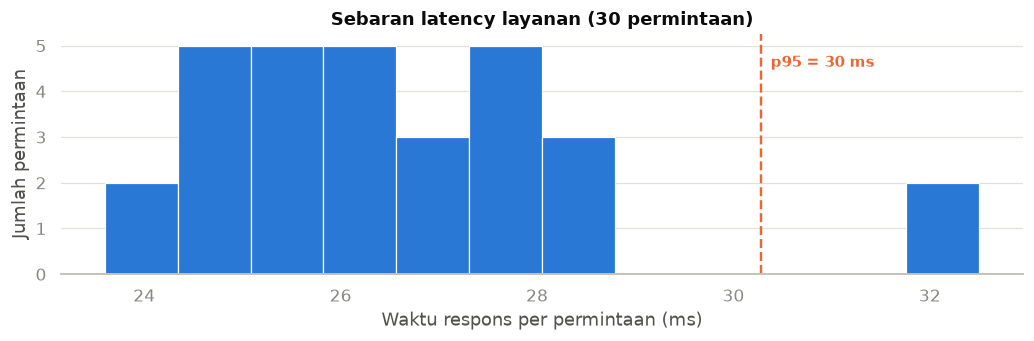

Ambang batasnya ditentukan kebutuhan bisnis, bukan angka mutlak:
  aplikasi tatap muka  : < 200 ms terasa langsung oleh pengguna
  proses batch malam   : hitungan detik masih wajar


In [45]:
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.hist(waktu_api, bins=12, color=BIRU, edgecolor="white", linewidth=0.8)

p95 = np.percentile(waktu_api, 95)
ax.axvline(p95, color=ORANYE, linestyle="--", linewidth=1.6)
ax.annotate(f"p95 = {p95:.0f} ms", xy=(p95, ax.get_ylim()[1] * 0.88),
            xytext=(6, 0), textcoords="offset points", color=ORANYE,
            fontsize=9.5, fontweight="bold", va="center")

ax.set_xlabel("Waktu respons per permintaan (ms)")
ax.set_ylabel("Jumlah permintaan")
ax.set_title(f"Sebaran latency layanan ({N_PERMINTAAN} permintaan)")
ax.grid(axis="x", visible=False)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

print("Ambang batasnya ditentukan kebutuhan bisnis, bukan angka mutlak:")
print("  aplikasi tatap muka  : < 200 ms terasa langsung oleh pengguna")
print("  proses batch malam   : hitungan detik masih wajar")

### 8.2 Log prediksi

Tanpa catatan, tidak ada yang bisa dipantau. Karena itu setiap permintaan dicatat: apa yang masuk,
apa yang dijawab, dan berapa lama prosesnya.

Log ini punya dua masa pakai. Sekarang isinya dipakai untuk memantau **distribusi data masuk**
(8.3) dan **latency**. Nanti, begitu keputusan kredit yang sebenarnya diketahui (nasabah lancar
atau gagal bayar), kolom prediksi tinggal dibandingkan dengan kenyataan - dan di situlah accuracy,
precision, dan recall produksi bisa dihitung.

In [46]:
FOLDER_LOG = Path("log")
FOLDER_LOG.mkdir(exist_ok=True)
BERKAS_LOG = FOLDER_LOG / "prediksi_log.csv"

catatan = []
for i in range(20):
    baris = X_test.iloc[[i]]
    muat = time.perf_counter()
    respons = requests.post(
        "http://127.0.0.1:5000/predict",
        json={"data": json.loads(baris.to_json(orient="records"))[0]},
    )
    lama = (time.perf_counter() - muat) * 1000
    jawaban = respons.json()

    catatan.append({
        "waktu": pd.Timestamp.now().round("s"),
        "umur": int(baris["Age"].iloc[0]),
        "plafon": int(baris["Credit amount"].iloc[0]),
        "prediksi": jawaban["prediction"][0],
        "peluang_bad": jawaban["probability_bad"][0],
        "latency_ms": round(lama, 1),
    })

log = pd.DataFrame(catatan)
# mode="a" = menambah di baris paling bawah, bukan menimpa; header hanya ditulis sekali.
log.to_csv(BERKAS_LOG, mode="a", header=not BERKAS_LOG.exists(), index=False)

print(f"{len(log)} permintaan dicatat ke {BERKAS_LOG}")
print(f"Total baris di berkas log sekarang: {sum(1 for _ in BERKAS_LOG.open()) - 1}")
print()
log.head(8)

20 permintaan dicatat ke log/prediksi_log.csv
Total baris di berkas log sekarang: 20



,waktu,umur,plafon,prediksi,peluang_bad,latency_ms
0,2026-10-15 04:44:41,42,2427,good,0.06,25.2
1,2026-10-15 04:44:41,29,3990,good,0.48,26.1
2,2026-10-15 04:44:41,48,12204,good,0.38,26.8
3,2026-10-15 04:44:41,40,1597,good,0.09,27.1
4,2026-10-15 04:44:41,37,12389,good,0.35,25.3
5,2026-10-15 04:44:41,42,409,good,0.26,35.3
6,2026-10-15 04:44:41,54,2255,good,0.01,26.9
7,2026-10-15 04:44:41,65,2600,good,0.36,33.2


### 8.3 Data drift

Data drift terjadi ketika data yang masuk ke model sudah tidak mirip lagi dengan data yang dipakai
saat melatih. Model tidak pernah tahu hal itu - ia akan tetap menjawab dengan yakin, padahal
jawabannya makin tidak relevan. Karena itu drift harus diukur dari luar.

Ukuran yang lazim dipakai adalah **PSI (Population Stability Index)**:

| Nilai PSI | Artinya | Tindakan |
|---|---|---|
| < 0,10 | Distribusi masih sama | lanjut seperti biasa |
| 0,10 - 0,25 | Mulai bergeser | pantau lebih rapat |
| > 0,25 | Drift signifikan | selidiki, siapkan pelatihan ulang |

Distribusi kolom numerik diukur dengan PSI. Untuk kolom kategorikal, yang dibandingkan adalah
proporsi tiap kategori (total variation distance).

In [47]:
def psi(nilai_latih, nilai_baru, n_bin=10):
    """PSI: 0 = distribusi sama, > 0,25 = drift yang perlu ditindaklanjuti."""
    # Batas bin diambil dari data latih (per-desil), lalu dipakai untuk kedua data.
    batas = np.unique(np.quantile(nilai_latih, np.linspace(0, 1, n_bin + 1)))
    batas[0], batas[-1] = -np.inf, np.inf

    prop_latih = np.histogram(nilai_latih, bins=batas)[0] / len(nilai_latih)
    prop_baru = np.histogram(nilai_baru, bins=batas)[0] / len(nilai_baru)
    # Proporsi nol diganti angka sangat kecil supaya log(0) tidak muncul.
    prop_latih = np.clip(prop_latih, 1e-6, None)
    prop_baru = np.clip(prop_baru, 1e-6, None)
    return float(np.sum((prop_baru - prop_latih) * np.log(prop_baru / prop_latih)))


def pergeseran_kategori(kolom, data_latih, data_baru):
    """Total variation distance: 0 = proporsi kategori identik, 1 = sama sekali berbeda."""
    a = data_latih[kolom].value_counts(normalize=True)
    b = data_baru[kolom].value_counts(normalize=True)
    kategori = a.index.union(b.index)
    return float(0.5 * (a.reindex(kategori, fill_value=0)
                        - b.reindex(kategori, fill_value=0)).abs().sum())


# Batch A - nasabah baru yang masih sejenis dengan data latih.
batch_normal = X_test.sample(150, random_state=RANDOM_STATE).copy()

# Batch B - nasabah baru setelah kondisi bergeser: peminjam lebih tua, plafon lebih besar
# (misal karena inflasi), dan sebagian besar mengajukan kredit untuk barang elektronik.
batch_drift = batch_normal.copy()
batch_drift["Age"] = batch_drift["Age"] + 4
batch_drift["Credit amount"] = (batch_drift["Credit amount"] * 1.3).round()
batch_drift.loc[batch_drift.index[:90], "Purpose"] = "radio/TV"

tabel_psi = pd.DataFrame({
    "batch normal": [psi(X_train[k], batch_normal[k]) for k in KOLOM_NUMERIK],
    "batch bergeser": [psi(X_train[k], batch_drift[k]) for k in KOLOM_NUMERIK],
}, index=KOLOM_NUMERIK).round(3)

print("PSI kolom numerik (dibandingkan dengan data train):")
print(tabel_psi.to_string())
print()
print("Pergeseran proporsi kategori:")
for kolom in ["Purpose", "Housing"]:
    print(f"  {kolom:9s}: normal {pergeseran_kategori(kolom, X_train, batch_normal):.3f}"
          f"  |  bergeser {pergeseran_kategori(kolom, X_train, batch_drift):.3f}")

PSI kolom numerik (dibandingkan dengan data train):
               batch normal  batch bergeser
Age                   0.048           0.888
Credit amount         0.093           0.335
Duration              0.118           0.118

Pergeseran proporsi kategori:
  Purpose  : normal 0.054  |  bergeser 0.412
  Housing  : normal 0.050  |  bergeser 0.050


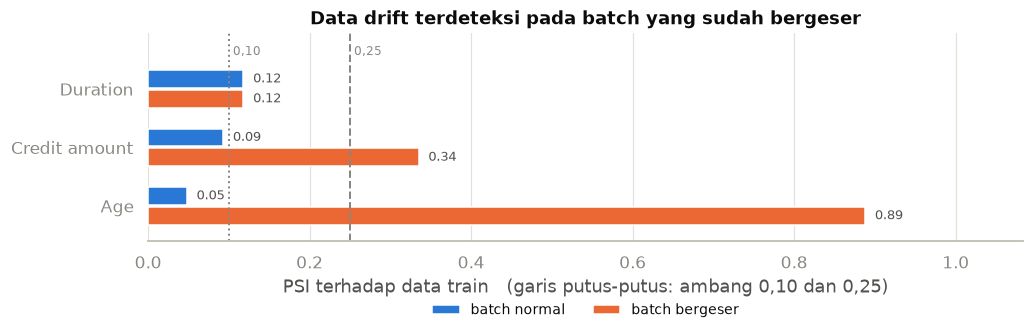

In [48]:
fig, ax = plt.subplots(figsize=(9.5, 3.3))
y = np.arange(len(KOLOM_NUMERIK))
tinggi = 0.34

ax.barh(y + tinggi / 2, tabel_psi["batch normal"], tinggi * 0.9,
        color=BIRU, label="batch normal")
ax.barh(y - tinggi / 2, tabel_psi["batch bergeser"], tinggi * 0.9,
        color=ORANYE, label="batch bergeser")

for i, kolom in enumerate(KOLOM_NUMERIK):
    for offset, seri in [(tinggi / 2, "batch normal"), (-tinggi / 2, "batch bergeser")]:
        nilai = tabel_psi.loc[kolom, seri]
        ax.text(nilai + 0.012, i + offset, f"{nilai:.2f}", va="center",
                fontsize=8.5, color=TINTA2)

# Dua ambang PSI digambar sebagai garis acuan. Keterangannya ditaruh di label sumbu,
# karena pada skala ini tulisan panjang di dalam grafik akan saling bertabrakan.
ax.axvline(0.10, color=ABU, linestyle=":", linewidth=1.3)
ax.axvline(0.25, color=ABU, linestyle="--", linewidth=1.3)
ax.text(0.105, len(KOLOM_NUMERIK) - 0.42, "0,10", fontsize=8, color=ABU)
ax.text(0.255, len(KOLOM_NUMERIK) - 0.42, "0,25", fontsize=8, color=ABU)

ax.set_yticks(y)
ax.set_yticklabels(KOLOM_NUMERIK)
ax.set_xlim(0, max(tabel_psi.to_numpy().max() * 1.22, 0.4))
ax.set_ylim(-0.6, len(KOLOM_NUMERIK) - 0.05)
ax.set_xlabel("PSI terhadap data train   (garis putus-putus: ambang 0,10 dan 0,25)")
ax.set_title("Data drift terdeteksi pada batch yang sudah bergeser")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.24),
          ncol=2, fontsize=9)
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

### 8.4 Menghentikan service

Service Flask di notebook ini dipakai sampai bagian 8 saja - bagian 9 hanya berlatih dan menilai
model, tanpa memerlukan API. Sesudah ini port 5000 dibebaskan lagi.

In [49]:
if server is not None:
    server.shutdown()
    print("Service dihentikan. Port 5000 bebas lagi.")
else:
    print("Service dijalankan dari terminal lain - hentikan dengan Ctrl+C di terminal itu.")

Service dihentikan. Port 5000 bebas lagi.


---
## 9. Data Evaluation

Bayangkan kita harus memilih satu model dari sepuluh model yang tersedia. Salah satu cara yang
mudah: latih semuanya, bandingkan tingkat erornya di test set, ambil yang paling kecil - misalnya
5% - lalu bawa ke produksi. Setelah dipakai produksi, erornya ternyata 15%.

Kenapa bisa begitu? Karena test set itu dipakai **berulang kali** untuk memilih. Secara sadar atau
tidak, kita memilih model yang kebetulan paling cocok dengan 200 baris test set itu - bukan model
yang paling baik secara umum. Akibatnya skor di test set terlalu optimistis, dan modelnya kecewa
saat bertemu data baru.

Solusinya: tambahkan **validation set** untuk memilih, dan simpan test set hanya untuk penilaian
terakhir.

### 9.1 Masalahnya: test set dipakai untuk memilih

Di bawah ini sembilan kandidat dilatih, semuanya dinilai pada test set yang sama, lalu diurutkan.
Perhatikan berapa banyak keputusan yang kita ambil hanya dari satu set data berisi 200 baris.

In [50]:
kandidat = {}
for C in [0.01, 1, 100]:
    kandidat[f"LR C={C}"] = LogisticRegression(C=C, max_iter=1000,
                                              random_state=RANDOM_STATE,
                                              class_weight="balanced")
for kedalaman in [3, 10, None]:
    kandidat[f"DT depth={kedalaman}"] = DecisionTreeClassifier(
        max_depth=kedalaman, min_samples_split=10, min_samples_leaf=5,
        random_state=RANDOM_STATE, class_weight="balanced")
for n in [50, 100, 300]:
    kandidat[f"RF {n}"] = RandomForestClassifier(n_estimators=n,
                                                 random_state=RANDOM_STATE,
                                                 class_weight="balanced")

skor_test = []
for nama, estimator in kandidat.items():
    pipa = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipa.fit(X_train, y_train)
    skor_test.append(evaluasi(nama, pipa, X_test, y_test))

tabel_test = pd.DataFrame(skor_test).set_index("Model").sort_values("ROC-AUC", ascending=False)
with pd.option_context("display.float_format", "{:.3f}".format):
    display(tabel_test.round(3))

juara_test = tabel_test.index[0]
skor_juara_test = tabel_test.loc[juara_test, "ROC-AUC"]
print(f"Terbaik menurut test set : {juara_test} (ROC-AUC {skor_juara_test:.3f})")
print("Angka inilah yang terlalu optimistis - diperiksa lagi di 9.3.")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
RF 300,0.705,0.507,0.633,0.563,0.765
RF 50,0.705,0.506,0.667,0.576,0.761
RF 100,0.705,0.506,0.650,0.569,0.761
LR C=1,0.645,0.446,0.750,0.559,0.753
LR C=100,0.645,0.446,0.750,0.559,0.751
LR C=0.01,0.665,0.463,0.733,0.568,0.747
DT depth=3,0.595,0.416,0.867,0.562,0.710
DT depth=None,0.630,0.417,0.583,0.486,0.680
DT depth=10,0.610,0.400,0.600,0.480,0.669


Terbaik menurut test set : RF 300 (ROC-AUC 0.765)
Angka inilah yang terlalu optimistis - diperiksa lagi di 9.3.


### 9.2 Validation set (holdout validation)

Validation set adalah bagian dari data train yang dipakai untuk menilai model pada tahap awal.
Alurnya:

1. Data train dipecah lagi menjadi **train** dan **validation**. Test set disisihkan, tidak disentuh.
2. Semua kandidat dilatih pada train dan dinilai pada validation set.
3. Model terbaik dipilih dari skor validation.
4. Model terpilih **dilatih ulang memakai seluruh data train** (train + validation) agar datanya
   kembali utuh.
5. Penilaian terakhir dilakukan sekali saja di test set.

Soal ukuran: validation set yang terlalu kecil membuat pemilihan tidak stabil, yang terlalu besar
membuat data latih saat seleksi jadi sedikit. Jalan tengah yang umum adalah 80:20, seperti di bawah.

In [51]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,          # 20% dari data train menjadi validation set
    random_state=RANDOM_STATE,
    stratify=y_train,       # proporsi good/bad tetap terjaga
)

print(f"train      : {len(X_tr):4d} baris")
print(f"validation : {len(X_val):4d} baris   <- untuk memilih model")
print(f"test       : {len(X_test):4d} baris   <- disimpan, dibuka sekali di akhir")

train      :  640 baris
validation :  160 baris   <- untuk memilih model
test       :  200 baris   <- disimpan, dibuka sekali di akhir


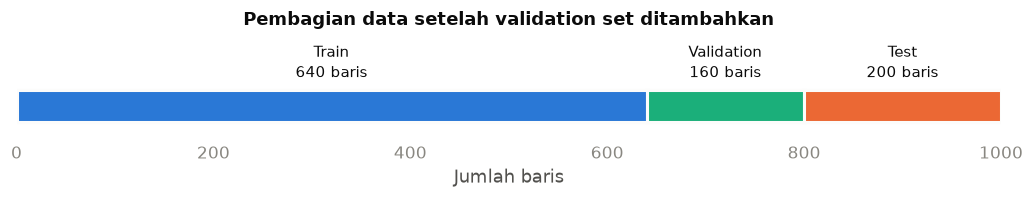

In [52]:
fig, ax = plt.subplots(figsize=(9.5, 1.9))
kiri = 0
for nama, jumlah, warna in [("Train", len(X_tr), BIRU),
                            ("Validation", len(X_val), "#1baf7a"),
                            ("Test", len(X_test), ORANYE)]:
    ax.barh(0, jumlah, left=kiri, height=0.4, color=warna,
            edgecolor="#fcfcfb", linewidth=2)
    # Label ditaruh di atas batang: potongan Validation dan Test terlalu sempit
    # untuk memuat tulisan di dalam batangnya.
    ax.text(kiri + jumlah / 2, 0.3, f"{nama}\n{jumlah} baris", ha="center", va="bottom",
            color=TINTA, fontsize=9.5, linespacing=1.4)
    kiri += jumlah

ax.set_xlim(0, kiri)
ax.set_ylim(-0.32, 0.82)
ax.set_yticks([])
ax.set_xlabel("Jumlah baris")
ax.set_title("Pembagian data setelah validation set ditambahkan", pad=10)
ax.grid(visible=False)
sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.show()

In [53]:
# Semua kandidat dilatih HANYA pada data train, lalu dinilai pada validation set.
skor_val = []
for nama, estimator in kandidat.items():
    pipa = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipa.fit(X_tr, y_tr)
    skor_val.append(evaluasi(nama, pipa, X_val, y_val))

tabel_val = pd.DataFrame(skor_val).set_index("Model").sort_values("ROC-AUC", ascending=False)
with pd.option_context("display.float_format", "{:.3f}".format):
    display(tabel_val.round(3))

juara_val = tabel_val.index[0]
print(f"Terbaik menurut validation set : {juara_val} (ROC-AUC {tabel_val.loc[juara_val, 'ROC-AUC']:.3f})")

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
LR C=1,0.769,0.587,0.771,0.667,0.794
LR C=100,0.756,0.571,0.750,0.649,0.791
LR C=0.01,0.744,0.552,0.771,0.643,0.776
RF 300,0.731,0.561,0.479,0.517,0.751
DT depth=3,0.694,0.492,0.625,0.550,0.744
RF 50,0.694,0.490,0.521,0.505,0.730
RF 100,0.719,0.533,0.500,0.516,0.728
DT depth=10,0.669,0.464,0.667,0.547,0.702
DT depth=None,0.669,0.460,0.604,0.523,0.701


Terbaik menurut validation set : LR C=1 (ROC-AUC 0.794)


In [54]:
# Model terpilih dilatih ULANG memakai seluruh data train (train + validation),
# supaya data yang dipakai model final lebih banyak daripada saat diseleksi.
pipa_juara_val = Pipeline([("preprocessor", preprocessor), ("model", kandidat[juara_val])])
pipa_juara_val.fit(X_train, y_train)

skor_akhir = evaluasi(juara_val, pipa_juara_val, X_test, y_test)

banding = pd.DataFrame({
    "ROC-AUC validation": [tabel_val.loc[juara_val, "ROC-AUC"]],
    "ROC-AUC test": [skor_akhir["ROC-AUC"]],
    "F1 validation": [tabel_val.loc[juara_val, "F1"]],
    "F1 test": [skor_akhir["F1"]],
    "Recall validation": [tabel_val.loc[juara_val, "Recall"]],
    "Recall test": [skor_akhir["Recall"]],
}, index=[juara_val])

with pd.option_context("display.float_format", "{:.3f}".format):
    display(banding.round(3))

print("Skor validation dan test tidak harus sama persis - keduanya sampel yang berbeda.")
print("Yang penting: keputusan memilih model tidak lagi diambil dari test set.")
print()
print(f"Terbaik di test set (cara 9.1)   : {juara_test}")
print(f"Terbaik di validation set (9.2)  : {juara_val}")

,ROC-AUC validation,ROC-AUC test,F1 validation,F1 test,Recall validation,Recall test
LR C=1,0.794,0.753,0.667,0.559,0.771,0.750


Skor validation dan test tidak harus sama persis - keduanya sampel yang berbeda.
Yang penting: keputusan memilih model tidak lagi diambil dari test set.

Terbaik di test set (cara 9.1)   : RF 300
Terbaik di validation set (9.2)  : LR C=1


### 9.3 K-Fold Cross Validation

Holdout validation masih menyisakan satu kelemahan: hasilnya bergantung pada satu kali pemecahan
data. Kalau pemecahannya kebetulan kurang beruntung, model yang terpilih pun kurang tepat.

**K-Fold Cross Validation** mengatasi itu. Data dibagi menjadi K lipatan. Setiap lipatan mendapat
giliran menjadi data uji tepat satu kali, sementara lipatan sisanya menjadi data latih. Semua baris
akhirnya ikut diuji, dan yang kita pakai adalah **rata-rata** skornya - jauh lebih tahan keberuntungan
daripada satu kali split.

Satu hal yang wajib diperhatikan: yang dimasukkan ke cross validation adalah **pipeline**, bukan
modelnya saja. Dengan begitu `StandardScaler` dan `OneHotEncoder` di-fit ulang di dalam setiap
lipatan, sehingga data uji tiap lipatan tidak pernah ikut mempengaruhi hasil scaling - tidak ada
kebocoran data.

In [55]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate

# Yang dianggap "positif" di kasus ini adalah nasabah berisiko (bad), jadi labelnya
# diubah dulu menjadi angka (bad = 1). Dengan begitu seluruh metrik pasti menghitung
# kelas yang benar - sama seperti di fungsi evaluasi() pada bagian 6.
y_train_bin = (y_train == "bad").astype(int)

SKOR = {
    "roc_auc": "roc_auc",
    "f1": make_scorer(f1_score, pos_label=1),
    "accuracy": "accuracy",
}

# stratify: proporsi good/bad di tiap lipatan dijaga sama seperti data aslinya.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Nama yang enak dibaca -> nama kandidat di 9.1, supaya tabelnya bisa disandingkan.
model_dibanding = {
    "Logistic Regression": "LR C=1",
    "Decision Tree": "DT depth=10",
    "Random Forest": "RF 100",
}

hasil_cv = {}
for nama, kunci in model_dibanding.items():
    pipa = Pipeline([("preprocessor", preprocessor), ("model", kandidat[kunci])])
    hasil_cv[nama] = cross_validate(pipa, X_train, y_train_bin, cv=cv,
                                    scoring=SKOR, n_jobs=-1)

print("ROC-AUC tiap lipatan (n = 800 baris data train):\n")
for nama, keluaran in hasil_cv.items():
    skor = keluaran["test_roc_auc"]
    lipatan = "  ".join(f"{s:.3f}" for s in skor)
    print(f"{nama:20s} {lipatan}   rata-rata {skor.mean():.3f} ± {skor.std():.3f}")

ROC-AUC tiap lipatan (n = 800 baris data train):

Logistic Regression  0.714  0.883  0.672  0.756  0.722   rata-rata 0.749 ± 0.072
Decision Tree        0.641  0.805  0.630  0.630  0.665   rata-rata 0.674 ± 0.067
Random Forest        0.715  0.844  0.660  0.758  0.737   rata-rata 0.743 ± 0.060


In [56]:
ringkas_cv = pd.DataFrame({
    "ROC-AUC rata-rata": [hasil_cv[n]["test_roc_auc"].mean() for n in model_dibanding],
    "simpangan baku": [hasil_cv[n]["test_roc_auc"].std() for n in model_dibanding],
    "F1 rata-rata": [hasil_cv[n]["test_f1"].mean() for n in model_dibanding],
    "Accuracy rata-rata": [hasil_cv[n]["test_accuracy"].mean() for n in model_dibanding],
}, index=list(model_dibanding)).round(3)

# Sebagai pembanding: skor test set dari kandidat yang sama.
ringkas_cv["ROC-AUC di test set"] = [
    tabel_test.loc[kunci, "ROC-AUC"] for kunci in model_dibanding.values()
]
ringkas_cv["selisih"] = (ringkas_cv["ROC-AUC di test set"] - ringkas_cv["ROC-AUC rata-rata"]).round(3)

with pd.option_context("display.float_format", "{:.3f}".format):
    display(ringkas_cv.round(3))

print("Kolom 'selisih' bukan ukuran kesalahan model: cross validation dan test set diukur")
print("pada baris data yang berbeda, jadi angkanya memang tidak akan sama persis.")
print()
selisih_lr_rf = abs(ringkas_cv.loc["Logistic Regression", "ROC-AUC rata-rata"]
                    - ringkas_cv.loc["Random Forest", "ROC-AUC rata-rata"])
print("Yang justru paling penting dibaca dari tabel ini:")
print(f"  simpangan baku antar lipatan : {ringkas_cv['simpangan baku'].min():.3f} - "
      f"{ringkas_cv['simpangan baku'].max():.3f}")
print(f"  selisih antar dua model teratas  : {selisih_lr_rf:.3f}")
print()
print("Goyangan antar lipatan jauh lebih besar daripada selisih antar model, jadi beda sekecil")
print("itu belum bisa disebut keunggulan.")
print()
print("Urutan rata-rata cross validation:")
for nama, nilai in ringkas_cv["ROC-AUC rata-rata"].sort_values(ascending=False).items():
    print(f"  {nama:20s} {nilai:.3f}")

,ROC-AUC rata-rata,simpangan baku,F1 rata-rata,Accuracy rata-rata,ROC-AUC di test set,selisih
Logistic Regression,0.749,0.072,0.578,0.691,0.753,0.004
Decision Tree,0.674,0.067,0.483,0.625,0.669,-0.005
Random Forest,0.743,0.060,0.526,0.704,0.761,0.018


Kolom 'selisih' bukan ukuran kesalahan model: cross validation dan test set diukur
pada baris data yang berbeda, jadi angkanya memang tidak akan sama persis.

Yang justru paling penting dibaca dari tabel ini:
  simpangan baku antar lipatan : 0.060 - 0.072
  selisih antar dua model teratas  : 0.006

Goyangan antar lipatan jauh lebih besar daripada selisih antar model, jadi beda sekecil
itu belum bisa disebut keunggulan.

Urutan rata-rata cross validation:
  Logistic Regression  0.749
  Random Forest        0.743
  Decision Tree        0.674


In [57]:
# Pembanding langsung dengan cara 9.1: pemenang di test set dinilai ulang memakai
# cross validation. Selisih kedua angka inilah besar rasa optimistisnya.
pipa_juara_test = Pipeline([("preprocessor", preprocessor), ("model", kandidat[juara_test])])
cv_juara_test = cross_validate(pipa_juara_test, X_train, y_train_bin, cv=cv,
                               scoring=SKOR, n_jobs=-1)
rata_cv_juara_test = cv_juara_test["test_roc_auc"].mean()

print(f"{juara_test} - pemenang di test set (cara 9.1):")
print(f"  ROC-AUC di test set             : {skor_juara_test:.3f}")
print(f"  ROC-AUC rata-rata cross valid.  : {rata_cv_juara_test:.3f}  (5 lipatan)")
print(f"  selisih                         : {skor_juara_test - rata_cv_juara_test:+.3f}")
print()

terbaik_cv = ringkas_cv["ROC-AUC rata-rata"].idxmax()
print(f"Model dengan rata-rata cross validation terbaik: {terbaik_cv}"
      f" ({ringkas_cv.loc[terbaik_cv, 'ROC-AUC rata-rata']:.3f})")
print()
print("Jadi model yang menang di test set tidak terbukti lebih baik setelah dinilai dengan cara")
print("yang jujur - keunggulannya tadi hilang. Inilah akibat memilih model dari test set.")

RF 300 - pemenang di test set (cara 9.1):
  ROC-AUC di test set             : 0.765
  ROC-AUC rata-rata cross valid.  : 0.745  (5 lipatan)
  selisih                         : +0.019

Model dengan rata-rata cross validation terbaik: Logistic Regression (0.749)

Jadi model yang menang di test set tidak terbukti lebih baik setelah dinilai dengan cara
yang jujur - keunggulannya tadi hilang. Inilah akibat memilih model dari test set.


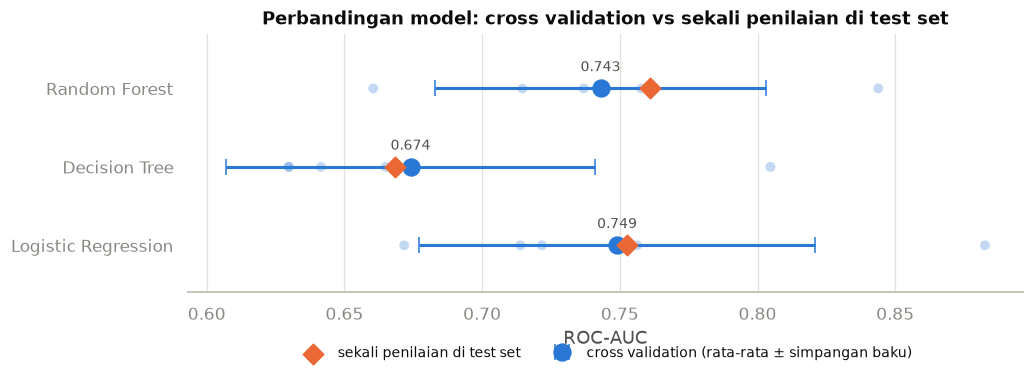

In [58]:
fig, ax = plt.subplots(figsize=(9.5, 3.6))
y = np.arange(len(model_dibanding))

# Titik-titik kecil: skor tiap lipatan, supaya sebarannya ikut terlihat.
for i, nama in enumerate(model_dibanding):
    skor = hasil_cv[nama]["test_roc_auc"]
    ax.scatter(skor, np.full(len(skor), i), s=42, color=BIRU, alpha=0.28,
               edgecolor="none", zorder=2)

# Titik besar: rata-rata, dengan garis simpangan baku.
ax.errorbar(ringkas_cv["ROC-AUC rata-rata"], y,
            xerr=ringkas_cv["simpangan baku"], fmt="o", markersize=11,
            color=BIRU, ecolor=BIRU, elinewidth=2, capsize=5, zorder=3,
            label="cross validation (rata-rata ± simpangan baku)")

# Belah ketupat: skor satu kali di test set, sebagai pembanding.
ax.scatter(ringkas_cv["ROC-AUC di test set"], y, s=90, marker="D",
           color=ORANYE, zorder=4, label="sekali penilaian di test set")

for i, nama in enumerate(model_dibanding):
    ax.text(ringkas_cv["ROC-AUC rata-rata"].iloc[i], i + 0.22,
            f"{ringkas_cv['ROC-AUC rata-rata'].iloc[i]:.3f}", ha="center",
            fontsize=9, color=TINTA2)

ax.set_yticks(y)
ax.set_yticklabels(list(model_dibanding))
ax.set_ylim(-0.6, len(model_dibanding) - 0.3)
ax.set_xlabel("ROC-AUC")
ax.set_title("Perbandingan model: cross validation vs sekali penilaian di test set")
# Legenda ditaruh di bawah sumbu supaya tidak menutupi baris "Logistic Regression".
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16),
          ncol=2, fontsize=9)
ax.grid(axis="y", visible=False)
sns.despine(ax=ax, left=True)
plt.tight_layout()
plt.show()

### 9.4 Model final

Model final dipilih dari **rata-rata cross validation**, bukan dari skor test set. Sesudah itu
model dilatih ulang memakai seluruh data train, disimpan sebagai artefak deployment, dan baru
kemudian test set dibuka - sekali saja - untuk laporan terakhir.

> **Catatan.** Artefak di `model/` ikut diperbarui di sini. Kalau cell pengujian API di bagian 7.4
> dijalankan ulang setelah ini, jawabannya datang dari model final yang baru - bukan lagi dari
> Random Forest yang dipakai saat bagian 7 berjalan.

In [59]:
juara_cv = ringkas_cv["ROC-AUC rata-rata"].idxmax()
print("Model final menurut cross validation :", juara_cv)
print("Model yang tadi di-deploy di bagian 7 : Random Forest")
print()

model_final = Pipeline([("preprocessor", preprocessor),
                        ("model", kandidat[model_dibanding[juara_cv]])])
model_final.fit(X_train, y_train)

# Artefak deployment diperbarui, supaya yang dilayani API adalah model hasil evaluasi,
# bukan model yang dipilih hanya karena menang di test set.
joblib.dump(model_final, BERKAS_JOBLIB)
with open(BERKAS_PICKLE, "wb") as file:
    pickle.dump(model_final, file)
print(f"Artefak di {FOLDER_MODEL}/ diperbarui dengan {juara_cv}.")
print()

# Penilaian terakhir - test set dibuka sekali saja, tidak dipakai untuk memilih lagi.
print(f"Laporan klasifikasi di test set - {juara_cv}")
print("=" * 58)
print(classification_report(y_test, model_final.predict(X_test), digits=3))

Model final menurut cross validation : Logistic Regression
Model yang tadi di-deploy di bagian 7 : Random Forest

Artefak di model/ diperbarui dengan Logistic Regression.

Laporan klasifikasi di test set - Logistic Regression
              precision    recall  f1-score   support

         bad      0.446     0.750     0.559        60
        good      0.848     0.600     0.703       140

    accuracy                          0.645       200
   macro avg      0.647     0.675     0.631       200
weighted avg      0.728     0.645     0.660       200



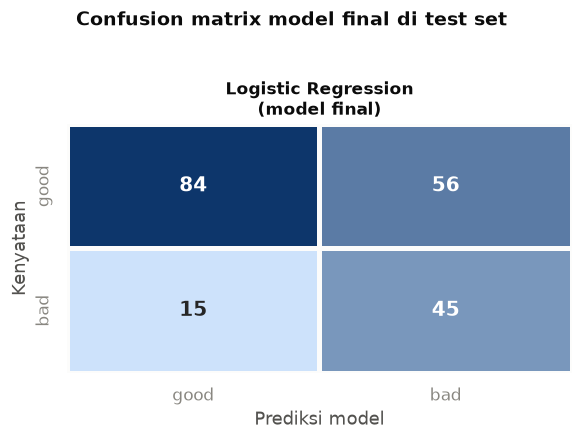

In [60]:
fig, ax = plt.subplots(figsize=(5.4, 3.8))
gambar_confusion(f"{juara_cv}\n(model final)", model_final, ax, y_test)
plt.suptitle("Confusion matrix model final di test set", y=1.04,
             fontsize=12.5, fontweight="bold", color=TINTA)
plt.tight_layout()
plt.show()

# Service API memuat model dari berkas, jadi model baru langsung terpakai
# begitu service dijalankan ulang.

---
## 10. Kesimpulan

Yang ditambahkan di bagian 7 sampai 9:

**Deployment**
- Model disimpan sebagai pipeline utuh ke `model/credit_risk_model.joblib` dan `.pkl`.
- Model dibungkus jadi service API (`testing_deploy.py`) dengan endpoint `POST /predict`
  dan `GET /health`, diuji lewat terminal (`curl`) maupun dari dalam notebook.

**Monitoring**
- Latency layanan diukur (median dan p95) dan dibandingkan dengan ongkos modelnya sendiri.
- Setiap permintaan dicatat ke `log/prediksi_log.csv` - bahan mentah untuk menghitung metrik
  produksi begitu label sebenarnya diketahui.
- Data drift diukur dengan PSI: batch yang masih sejenis aman, batch yang bergeser melewati ambang
  0,25.

**Data Evaluation**
- Mengukur error berulang kali pada test set yang sama membuat pemilihan model terlalu optimistis.
- Validation set memindahkan keputusan pemilihan model keluar dari test set.
- K-Fold Cross Validation membuat penilaian jauh lebih stabil karena seluruh data train bergiliran
  menjadi data uji, dan pipeline di-fit ulang di setiap lipatan sehingga tidak ada kebocoran data.
- Test set akhirnya dipakai sekali saja, untuk laporan terakhir.

Dengan urutan ini, model yang masuk produksi bukan model yang kebetulan paling cocok dengan test
set, melainkan model yang paling konsisten di seluruh data latih - dan sesudah berjalan, ada
mekanisme untuk mengetahui kalau performanya mulai turun.